# CSE465 — PVTv2-B0 + Mamba + RetinaNet (Augmented)

This is the **clean A1 Mamba notebook**.

It starts from the saved best checkpoint of:

`05_PVTv2B0_RetinaNet_Aug/weights/best.pt`

and fine-tunes:

`PVTv2-B0 → deep bidirectional Mamba → FPN → RetinaNet`

using the **same successful PVT augmentation policy**.

## Important Colab setup

Current Colab can default to PyTorch 2.11, while the official Mamba CUDA wheel
matrix currently stops at PyTorch 2.10. This notebook therefore:

1. pins PyTorch `2.10.0 + CUDA 12.8`,
2. restarts the session once if needed,
3. installs an **exact prebuilt Mamba CUDA wheel**,
4. refuses to fall back to a long source compilation,
5. runs a CUDA forward + backward Mamba smoke test before training.

### First use
- Select **T4 GPU** in Colab.
- Run the notebook from the top.
- If the first environment cell restarts the session, wait for Colab to reconnect,
  then run the notebook from the top **one more time**.
- On the second pass it will detect PyTorch 2.10 and continue normally.

## Experiment
- A0 saved baseline: PVTv2-B0 + FPN + RetinaNet + Aug
- A1: A0 + deep bidirectional Mamba
- Max fine-tuning epochs: 25
- Patience: 5
- Effective batch: 16
- Output folder:
  `MyDrive/Study Materials /CSE465/06_PVTv2B0_Mamba_RetinaNet_Aug/`

## 1. Colab environment — one-time PyTorch compatibility setup

**Use a T4 GPU runtime.**

The first time this cell runs on a default PyTorch 2.11 Colab runtime, it will
install the official PyTorch 2.10 / torchvision 0.25 CUDA 12.8 stack and then
**intentionally restart the Python session**.

After Colab reconnects, run the notebook from the top again. The cell will then
detect the correct versions and continue without another restart.

In [ ]:
import os
import sys
import time
import subprocess
from importlib import metadata

TARGET_TORCH = "2.10.0"
TARGET_TORCHVISION = "0.25.0"
TARGET_TORCHAUDIO = "2.10.0"

# GPU check without importing torch yet.
gpu_check = subprocess.run(
    ["nvidia-smi", "-L"],
    capture_output=True,
    text=True,
)

if gpu_check.returncode != 0:
    raise RuntimeError(
        "No NVIDIA GPU detected. In Colab choose "
        "Runtime > Change runtime type > T4 GPU, "
        "then run this cell again."
    )

print("GPU:")
print(gpu_check.stdout.strip())

try:
    installed_torch = metadata.version("torch")
except metadata.PackageNotFoundError:
    installed_torch = "not installed"

try:
    installed_tv = metadata.version("torchvision")
except metadata.PackageNotFoundError:
    installed_tv = "not installed"

print("\nCurrent package versions:")
print("torch      :", installed_torch)
print("torchvision:", installed_tv)

torch_ok = installed_torch.startswith(
    TARGET_TORCH
)

tv_ok = installed_tv.startswith(
    TARGET_TORCHVISION
)

if not (torch_ok and tv_ok):
    print(
        "\nInstalling the Mamba-compatible "
        "PyTorch 2.10 + CUDA 12.8 stack..."
    )

    start = time.perf_counter()

    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "--upgrade",
            f"torch=={TARGET_TORCH}",
            f"torchvision=={TARGET_TORCHVISION}",
            f"torchaudio=={TARGET_TORCHAUDIO}",
            "--index-url",
            "https://download.pytorch.org/whl/cu128",
        ],
        check=True,
    )

    print(
        f"✅ PyTorch stack installed in "
        f"{(time.perf_counter()-start)/60:.2f} min"
    )

    print(
        "\nThe session will restart now so the newly "
        "installed PyTorch libraries are loaded cleanly."
    )
    print(
        "After Colab reconnects, RUN THE NOTEBOOK "
        "FROM THE TOP ONE MORE TIME."
    )

    sys.stdout.flush()
    time.sleep(3)

    # Intentional kernel restart. Installed packages remain in the VM.
    os.kill(
        os.getpid(),
        9,
    )

print(
    "\n✅ Compatible PyTorch package versions already installed. "
    "No restart needed."
)

GPU:
GPU 0: Tesla T4 (UUID: GPU-8d010309-7dd3-9aba-99a4-0b1de233ae54)

Current package versions:
torch      : 2.10.0+cu128
torchvision: 0.25.0+cu128

✅ Compatible PyTorch package versions already installed. No restart needed.


## 2. Install dependencies + exact prebuilt Mamba CUDA wheel

This cell deliberately installs a **specific wheel URL** instead of asking pip
to build Mamba from source.

The wheel filename is generated from:
- Python version
- CUDA major version
- PyTorch major/minor version
- C++11 ABI setting

If the expected wheel is unavailable, the cell fails immediately rather than
silently spending a long time compiling CUDA code.

In [ ]:
import os
import sys
import time
import subprocess

# ------------------------------------------------------------
# Normal project dependencies
# ------------------------------------------------------------
print("Installing project dependencies...")

start = time.perf_counter()

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "setuptools==80.9.0",
        "wheel",
        "packaging",
        "ninja",
        "jedi>=0.16",
        "timm",
        "torchmetrics",
        "pycocotools",
        "einops",
    ],
    check=True,
)

print(
    f"✅ Project dependencies installed in "
    f"{(time.perf_counter()-start)/60:.2f} min"
)


# ------------------------------------------------------------
# Verify the pinned CUDA PyTorch stack
# ------------------------------------------------------------
import torch
import torchvision

print("\nEnvironment:")
print("Python      :", sys.version.split()[0])
print("Torch       :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("Torch CUDA  :", torch.version.cuda)
print("CUDA ready  :", torch.cuda.is_available())
print(
    "CXX11 ABI   :",
    torch._C._GLIBCXX_USE_CXX11_ABI,
)

if not torch.__version__.startswith(
    "2.10.0"
):
    raise RuntimeError(
        "PyTorch 2.10 is required for the prebuilt "
        "Mamba wheel used by this notebook. "
        "Rerun the previous environment cell."
    )

if not torchvision.__version__.startswith(
    "0.25.0"
):
    raise RuntimeError(
        "torchvision 0.25 is required with PyTorch 2.10."
    )

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable. Switch Colab to T4 GPU."
    )

if torch.version.cuda is None:
    raise RuntimeError(
        "CUDA-enabled PyTorch was not installed."
    )


# ------------------------------------------------------------
# Exact Mamba wheel URL
# ------------------------------------------------------------
MAMBA_VERSION = "2.3.2.post1"

py_tag = (
    f"cp{sys.version_info.major}"
    f"{sys.version_info.minor}"
)

torch_base = (
    torch.__version__
    .split("+")[0]
)

torch_mm = ".".join(
    torch_base.split(".")[:2]
)

cuda_major = (
    torch.version.cuda
    .split(".")[0]
)

abi = str(
    torch._C._GLIBCXX_USE_CXX11_ABI
).upper()

wheel_name = (
    f"mamba_ssm-{MAMBA_VERSION}"
    f"+cu{cuda_major}"
    f"torch{torch_mm}"
    f"cxx11abi{abi}"
    f"-{py_tag}-{py_tag}"
    f"-linux_x86_64.whl"
)

wheel_url = (
    "https://github.com/state-spaces/mamba/releases/download/"
    f"v{MAMBA_VERSION}/"
    f"{wheel_name}"
)

print("\nInstalling exact prebuilt Mamba CUDA wheel:")
print(wheel_name)

start = time.perf_counter()

try:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            wheel_url,
        ],
        check=True,
    )
except subprocess.CalledProcessError as exc:
    raise RuntimeError(
        "The exact prebuilt Mamba wheel could not be installed. "
        "This notebook intentionally does NOT fall back to slow "
        "source compilation.\n\nExpected wheel:\n"
        f"{wheel_url}\n\n"
        "Do not continue to training."
    ) from exc

print(
    f"✅ Prebuilt Mamba wheel installed in "
    f"{(time.perf_counter()-start)/60:.2f} min"
)


# ------------------------------------------------------------
# CUDA extension + forward/backward smoke test
# ------------------------------------------------------------
try:
    import selective_scan_cuda
    from mamba_ssm import Mamba
except Exception as exc:
    raise RuntimeError(
        "Mamba installed, but the CUDA selective-scan "
        "extension is not available."
    ) from exc

print(
    "✅ selective_scan_cuda import passed"
)

smoke_model = Mamba(
    d_model=256,
    d_state=16,
    d_conv=4,
    expand=2,
).cuda()

smoke_x = torch.randn(
    1,
    400,
    256,
    device="cuda",
    requires_grad=True,
)

smoke_y = smoke_model(
    smoke_x
)

if smoke_y.shape != smoke_x.shape:
    raise RuntimeError(
        "Unexpected Mamba output shape."
    )

if not torch.isfinite(
    smoke_y
).all():
    raise RuntimeError(
        "Non-finite values found in Mamba smoke test."
    )

smoke_y.mean().backward()

print(
    "✅ Mamba CUDA forward + backward test PASSED"
)
print(
    "Input/output:",
    tuple(smoke_x.shape),
)

del smoke_model
del smoke_x
del smoke_y

import gc
gc.collect()
torch.cuda.empty_cache()

print(
    "\n✅ Environment is ready for the Mamba experiment."
)

Installing project dependencies...
✅ Project dependencies installed in 0.35 min

Environment:
Python      : 3.13.15
Torch       : 2.10.0+cu128
Torchvision : 0.25.0+cu128
Torch CUDA  : 12.8
CUDA ready  : True
CXX11 ABI   : True

Installing exact prebuilt Mamba CUDA wheel:
mamba_ssm-2.3.2.post1+cu12torch2.10cxx11abiTRUE-cp313-cp313-linux_x86_64.whl
✅ Prebuilt Mamba wheel installed in 1.04 min
✅ selective_scan_cuda import passed
✅ Mamba CUDA forward + backward test PASSED
Input/output: (1, 400, 256)

✅ Environment is ready for the Mamba experiment.


## 3. Mount Google Drive

In [ ]:
from google.colab import drive

drive.mount(
    "/content/drive"
)

Mounted at /content/drive


## 4. Imports and reproducibility

In [ ]:
import os
import gc
import cv2
import time
import yaml
import random
import shutil
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import OrderedDict, defaultdict

import torch
import torchvision
import timm

from torch import nn
from torch.utils.data import Dataset, DataLoader

from torchvision.models.detection.retinanet import RetinaNet
from torchvision.transforms import v2
from torchvision import tv_tensors
from torchvision.ops import FeaturePyramidNetwork, box_iou
from torchvision.ops.feature_pyramid_network import LastLevelP6P7

from torchmetrics.detection.mean_ap import MeanAveragePrecision
from mamba_ssm import Mamba

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

DEVICE = torch.device(
    "cuda"
)

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is required for this experiment."
    )

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("timm:", timm.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("Mamba import: OK")

PyTorch: 2.10.0+cu128
Torchvision: 0.25.0+cu128
timm: 1.0.28
GPU: Tesla T4
Mamba import: OK


## 5. Drive folders — A0 source and A1 output

In [ ]:
CSE_ROOT = Path(
    "/content/drive/MyDrive/Study Materials /CSE465"
)

DATA_ZIP = (
    CSE_ROOT
    / "Prepared Dataset.zip"
)

# ------------------------------------------------------------
# READ-ONLY A0 source checkpoint
# ------------------------------------------------------------
A0_EXP_ROOT = (
    CSE_ROOT
    / "05_PVTv2B0_RetinaNet_Aug"
)

A0_BEST_PT = (
    A0_EXP_ROOT
    / "weights"
    / "best.pt"
)

# ------------------------------------------------------------
# NEW A1 experiment
# ------------------------------------------------------------
EXP_ROOT = (
    CSE_ROOT
    / "06_PVTv2B0_Mamba_RetinaNet_Aug"
)

WEIGHTS_DIR = (
    EXP_ROOT
    / "weights"
)

METRICS_DIR = (
    EXP_ROOT
    / "metrics"
)

PLOTS_DIR = (
    EXP_ROOT
    / "plots"
)

PREDICTIONS_DIR = (
    EXP_ROOT
    / "predictions"
)

CONFIG_DIR = (
    EXP_ROOT
    / "config"
)

for folder in [
    EXP_ROOT,
    WEIGHTS_DIR,
    METRICS_DIR,
    PLOTS_DIR,
    PREDICTIONS_DIR,
    CONFIG_DIR,
]:
    folder.mkdir(
        parents=True,
        exist_ok=True,
    )

BEST_PT = (
    WEIGHTS_DIR
    / "best.pt"
)

LAST_PT = (
    WEIGHTS_DIR
    / "last.pt"
)

INITIAL_PT = (
    WEIGHTS_DIR
    / "initial_from_A0.pt"
)

assert DATA_ZIP.exists(), (
    f"Dataset ZIP not found: {DATA_ZIP}"
)

assert A0_BEST_PT.exists(), (
    "A0 augmented checkpoint not found: "
    f"{A0_BEST_PT}"
)

print(
    "Dataset:",
    DATA_ZIP,
)

print(
    "A0 source:",
    A0_BEST_PT,
)

print(
    "A1 experiment:",
    EXP_ROOT,
)

Dataset: /content/drive/MyDrive/Study Materials /CSE465/Prepared Dataset.zip
A0 source: /content/drive/MyDrive/Study Materials /CSE465/05_PVTv2B0_RetinaNet_Aug/weights/best.pt
A1 experiment: /content/drive/MyDrive/Study Materials /CSE465/06_PVTv2B0_Mamba_RetinaNet_Aug


### Drive storage safety check

A previous experiment was lost because Google Drive had no free space.

This cell performs a temporary **128 MB real write test** inside the A1 output
folder and immediately deletes it. If Drive cannot accept the file, the
notebook stops **before training**.

In [ ]:
DRIVE_TEST_MB = 128

test_file = (
    EXP_ROOT
    / "_drive_write_test.bin"
)

print(
    f"Testing Google Drive write capacity "
    f"with {DRIVE_TEST_MB} MB..."
)

try:
    chunk = b"\0" * (
        1024 * 1024
    )

    with open(
        test_file,
        "wb",
    ) as f:
        for _ in range(
            DRIVE_TEST_MB
        ):
            f.write(chunk)

        f.flush()
        os.fsync(
            f.fileno()
        )

    written_mb = (
        test_file.stat().st_size
        / 1024**2
    )

    if written_mb < DRIVE_TEST_MB:
        raise RuntimeError(
            "Drive write test produced an incomplete file."
        )

    print(
        f"✅ Drive write test passed "
        f"({written_mb:.0f} MB)."
    )

finally:
    if test_file.exists():
        test_file.unlink()

print(
    "Temporary test file deleted."
)

Testing Google Drive write capacity with 128 MB...
✅ Drive write test passed (128 MB).
Temporary test file deleted.


## 6. Extract prepared dataset locally

In [ ]:
LOCAL_ROOT = Path("/content/CSE465_dataset")

if LOCAL_ROOT.exists():
    shutil.rmtree(LOCAL_ROOT)

LOCAL_ROOT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(DATA_ZIP, "r") as z:
    z.extractall(LOCAL_ROOT)

DATASET_DIR = LOCAL_ROOT / "Prepared Dataset"
DATA_YAML = DATASET_DIR / "data.yaml"

assert DATASET_DIR.exists()
assert DATA_YAML.exists()

print("Dataset extracted to:", DATASET_DIR)

Dataset extracted to: /content/CSE465_dataset/Prepared Dataset


## 7. Read dataset configuration

In [ ]:
with open(DATA_YAML, "r") as f:
    data_config = yaml.safe_load(f)

CLASS_NAMES = data_config["names"]
NUM_CLASSES = len(CLASS_NAMES)

print("Classes:", CLASS_NAMES)
print("Number of detection classes:", NUM_CLASSES)

for split in ["train", "val", "test"]:
    n_img = len(list((DATASET_DIR / "images" / split).glob("*")))
    n_lbl = len(list((DATASET_DIR / "labels" / split).glob("*.txt")))
    print(f"{split:5s}: {n_img} images | {n_lbl} labels")

Classes: ['finger', 'crack', 'black_core', 'thick_line', 'horizontal_dislocation', 'short_circuit', 'vertical_dislocation', 'star_crack', 'printing_error']
Number of detection classes: 9
train: 4418 images | 4418 labels
val  : 947 images | 947 labels
test : 949 images | 949 labels


## 8. A1 fine-tuning configuration

A1 starts from the best A0 augmented checkpoint and fine-tunes the newly
inserted Mamba block together with the original detector.

The A0 augmentation policy is kept **identical** so that the architectural
difference being tested is Mamba.

In [ ]:
IMAGE_SIZE = 640

BATCH_SIZE = 8
ACCUM_STEPS = 2
EFFECTIVE_BATCH = (
    BATCH_SIZE
    * ACCUM_STEPS
)

MAX_EPOCHS = 25
PATIENCE = 5
NUM_WORKERS = 2

WEIGHT_DECAY = 0.05
GRAD_CLIP = 1.0

# Differential fine-tuning LRs.
LR_PVT_BODY = 1e-5
LR_FPN_HEAD = 5e-5
LR_MAMBA = 1e-4

AMP = True

CONF_THRESHOLD = 0.25
MATCH_IOU_THRESHOLD = 0.50

# False for a brand-new A1 run.
# True only after a Colab disconnect if A1 last.pt exists.
RESUME = False

# ------------------------------------------------------------
# EXACT SAME augmentation as the successful A0 PVT Aug run.
# ------------------------------------------------------------
AUGMENTATION = {
    "brightness": 0.15,
    "brightness_p": 0.50,

    "contrast": 0.10,
    "contrast_p": 0.50,

    "gaussian_blur_p": 0.10,
    "gaussian_blur_kernel": 3,
    "gaussian_blur_sigma_min": 0.10,
    "gaussian_blur_sigma_max": 0.80,

    "gaussian_noise_p": 0.15,
    "gaussian_noise_std": 0.01,

    "fliplr": 0.50,
    "flipud": 0.50,

    "degrees": 0.0,
    "translate": 0.0,
    "scale": 0.0,
    "shear": 0.0,

    "mosaic": 0.0,
    "mixup": 0.0,
    "cutmix": 0.0,
    "copy_paste": 0.0,
    "erasing": 0.0,
}

MAMBA_CONFIG = {
    "placement":
        "deepest PVT feature before FPN",

    "d_model":
        256,

    "d_state":
        16,

    "d_conv":
        4,

    "expand":
        2,

    "bidirectional":
        True,

    "shared_forward_reverse_weights":
        True,

    "residual_gate_init":
        0.0,
}

training_config = {
    "model":
        "PVTv2-B0 + BiMamba + FPN + RetinaNet",

    "experiment":
        "A1_Aug_Mamba",

    "source_A0_checkpoint":
        str(A0_BEST_PT),

    "image_size":
        IMAGE_SIZE,

    "physical_batch_size":
        BATCH_SIZE,

    "gradient_accumulation":
        ACCUM_STEPS,

    "effective_batch_size":
        EFFECTIVE_BATCH,

    "max_epochs":
        MAX_EPOCHS,

    "patience":
        PATIENCE,

    "lr_pvt_body":
        LR_PVT_BODY,

    "lr_fpn_head":
        LR_FPN_HEAD,

    "lr_mamba":
        LR_MAMBA,

    "weight_decay":
        WEIGHT_DECAY,

    "seed":
        SEED,

    "augmentation":
        AUGMENTATION,

    "augmentation_scope":
        "train only, on-the-fly",

    "mamba":
        MAMBA_CONFIG,

    "detections_per_image":
        100,
}

with open(
    CONFIG_DIR
    / "training_config.yaml",
    "w",
) as f:
    yaml.safe_dump(
        training_config,
        f,
        sort_keys=False,
    )

print(
    training_config
)

{'model': 'PVTv2-B0 + BiMamba + FPN + RetinaNet', 'experiment': 'A1_Aug_Mamba', 'source_A0_checkpoint': '/content/drive/MyDrive/Study Materials /CSE465/05_PVTv2B0_RetinaNet_Aug/weights/best.pt', 'image_size': 640, 'physical_batch_size': 8, 'gradient_accumulation': 2, 'effective_batch_size': 16, 'max_epochs': 25, 'patience': 5, 'lr_pvt_body': 1e-05, 'lr_fpn_head': 5e-05, 'lr_mamba': 0.0001, 'weight_decay': 0.05, 'seed': 42, 'augmentation': {'brightness': 0.15, 'brightness_p': 0.5, 'contrast': 0.1, 'contrast_p': 0.5, 'gaussian_blur_p': 0.1, 'gaussian_blur_kernel': 3, 'gaussian_blur_sigma_min': 0.1, 'gaussian_blur_sigma_max': 0.8, 'gaussian_noise_p': 0.15, 'gaussian_noise_std': 0.01, 'fliplr': 0.5, 'flipud': 0.5, 'degrees': 0.0, 'translate': 0.0, 'scale': 0.0, 'shear': 0.0, 'mosaic': 0.0, 'mixup': 0.0, 'cutmix': 0.0, 'copy_paste': 0.0, 'erasing': 0.0}, 'augmentation_scope': 'train only, on-the-fly', 'mamba': {'placement': 'deepest PVT feature before FPN', 'd_model': 256, 'd_state': 16, 'd

## 9. Dataset class — same augmentation as A0

No augmentation variable is changed for the Mamba ablation.

Training:
- brightness ±15%, p=0.50
- contrast ±10%, p=0.50
- mild Gaussian blur, p=0.10
- mild Gaussian noise, p=0.15
- horizontal flip, p=0.50
- vertical flip, p=0.50

Validation and test remain deterministic and unaugmented.

In [ ]:
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff",
}


def letterbox_image(
    image,
    boxes,
    size=640,
    fill=114,
):
    h, w = image.shape[:2]

    scale = min(
        size / w,
        size / h,
    )

    new_w = int(
        round(w * scale)
    )

    new_h = int(
        round(h * scale)
    )

    resized = cv2.resize(
        image,
        (new_w, new_h),
        interpolation=cv2.INTER_LINEAR,
    )

    pad_x = (
        size - new_w
    ) // 2

    pad_y = (
        size - new_h
    ) // 2

    canvas = np.full(
        (size, size, 3),
        fill,
        dtype=np.uint8,
    )

    canvas[
        pad_y:pad_y + new_h,
        pad_x:pad_x + new_w,
    ] = resized

    boxes = np.asarray(
        boxes,
        dtype=np.float32,
    ).reshape(-1, 4)

    if len(boxes):
        boxes = boxes.copy()

        boxes[:, [0, 2]] = (
            boxes[:, [0, 2]]
            * scale
            + pad_x
        )

        boxes[:, [1, 3]] = (
            boxes[:, [1, 3]]
            * scale
            + pad_y
        )

    return canvas, boxes


train_transform = v2.Compose([
    v2.RandomApply(
        [
            v2.ColorJitter(
                brightness=AUGMENTATION["brightness"],
                contrast=0.0,
                saturation=0.0,
                hue=0.0,
            )
        ],
        p=AUGMENTATION["brightness_p"],
    ),

    v2.RandomApply(
        [
            v2.ColorJitter(
                brightness=0.0,
                contrast=AUGMENTATION["contrast"],
                saturation=0.0,
                hue=0.0,
            )
        ],
        p=AUGMENTATION["contrast_p"],
    ),

    v2.RandomApply(
        [
            v2.GaussianBlur(
                kernel_size=AUGMENTATION[
                    "gaussian_blur_kernel"
                ],
                sigma=(
                    AUGMENTATION[
                        "gaussian_blur_sigma_min"
                    ],
                    AUGMENTATION[
                        "gaussian_blur_sigma_max"
                    ],
                ),
            )
        ],
        p=AUGMENTATION["gaussian_blur_p"],
    ),

    v2.RandomHorizontalFlip(
        p=AUGMENTATION["fliplr"]
    ),

    v2.RandomVerticalFlip(
        p=AUGMENTATION["flipud"]
    ),
])


class PVDetectionDataset(Dataset):
    def __init__(
        self,
        dataset_dir,
        split,
        image_size=640,
        augment=False,
    ):
        self.image_dir = (
            Path(dataset_dir)
            / "images"
            / split
        )

        self.label_dir = (
            Path(dataset_dir)
            / "labels"
            / split
        )

        self.split = split
        self.image_size = image_size
        self.augment = augment

        self.images = sorted(
            p
            for p in self.image_dir.iterdir()
            if p.suffix.lower()
            in IMAGE_EXTENSIONS
        )

    def __len__(self):
        return len(self.images)

    def _load_raw(self, idx):
        image_path = self.images[idx]

        label_path = (
            self.label_dir
            / f"{image_path.stem}.txt"
        )

        image = cv2.imread(
            str(image_path)
        )

        if image is None:
            raise RuntimeError(
                f"Could not read: {image_path}"
            )

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB,
        )

        h, w = image.shape[:2]

        boxes = []
        labels = []

        if label_path.exists():
            text = (
                label_path
                .read_text()
                .strip()
            )

            if text:
                for line in text.splitlines():
                    (
                        cls_id,
                        xc,
                        yc,
                        bw,
                        bh,
                    ) = map(
                        float,
                        line.split(),
                    )

                    x1 = (
                        xc - bw / 2
                    ) * w

                    y1 = (
                        yc - bh / 2
                    ) * h

                    x2 = (
                        xc + bw / 2
                    ) * w

                    y2 = (
                        yc + bh / 2
                    ) * h

                    boxes.append(
                        [x1, y1, x2, y2]
                    )

                    labels.append(
                        int(cls_id)
                    )

        boxes = np.asarray(
            boxes,
            dtype=np.float32,
        ).reshape(-1, 4)

        labels = np.asarray(
            labels,
            dtype=np.int64,
        ).reshape(-1)

        return (
            image,
            boxes,
            labels,
            str(image_path),
        )

    def __getitem__(self, idx):
        (
            image,
            boxes,
            labels,
            image_path,
        ) = self._load_raw(idx)

        image, boxes = letterbox_image(
            image,
            boxes,
            size=self.image_size,
        )

        image = tv_tensors.Image(
            torch.from_numpy(
                np.ascontiguousarray(
                    image
                )
            ).permute(2, 0, 1)
        )

        boxes = tv_tensors.BoundingBoxes(
            torch.as_tensor(
                boxes,
                dtype=torch.float32,
            ).reshape(-1, 4),
            format="XYXY",
            canvas_size=(
                self.image_size,
                self.image_size,
            ),
        )

        target = {
            "boxes": boxes,
            "labels": torch.as_tensor(
                labels,
                dtype=torch.int64,
            ),
        }

        original_box_count = len(
            target["boxes"]
        )

        if self.augment:
            image, target = train_transform(
                image,
                target,
            )

        image = (
            image
            .as_subclass(torch.Tensor)
            .to(torch.float32)
            / 255.0
        )

        if (
            self.augment
            and random.random()
            < AUGMENTATION["gaussian_noise_p"]
        ):
            image = torch.clamp(
                image
                + torch.randn_like(image)
                * AUGMENTATION[
                    "gaussian_noise_std"
                ],
                0.0,
                1.0,
            )

        boxes_out = (
            target["boxes"]
            .as_subclass(torch.Tensor)
            .to(torch.float32)
        )

        labels_out = (
            target["labels"]
            .to(torch.int64)
        )

        if len(boxes_out) != original_box_count:
            raise RuntimeError(
                f"Unexpected box-count change: "
                f"{image_path}"
            )

        if len(boxes_out):
            if not torch.isfinite(
                boxes_out
            ).all():
                raise RuntimeError(
                    f"Non-finite box: "
                    f"{image_path}"
                )

            if not (
                (
                    boxes_out[:, 2]
                    > boxes_out[:, 0]
                ).all()
                and (
                    boxes_out[:, 3]
                    > boxes_out[:, 1]
                ).all()
            ):
                raise RuntimeError(
                    f"Invalid box: "
                    f"{image_path}"
                )

        target_out = {
            "boxes": boxes_out,
            "labels": labels_out,
            "image_id": torch.tensor(
                [idx],
                dtype=torch.int64,
            ),
        }

        return (
            image,
            target_out,
            image_path,
        )


def collate_fn(batch):
    images, targets, paths = zip(*batch)

    return (
        list(images),
        list(targets),
        list(paths),
    )


def seed_worker(worker_id):
    worker_seed = (
        torch.initial_seed()
        % 2**32
    )

    np.random.seed(worker_seed)
    random.seed(worker_seed)


loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)


train_dataset = PVDetectionDataset(
    DATASET_DIR,
    "train",
    IMAGE_SIZE,
    augment=True,
)

val_dataset = PVDetectionDataset(
    DATASET_DIR,
    "val",
    IMAGE_SIZE,
    augment=False,
)

test_dataset = PVDetectionDataset(
    DATASET_DIR,
    "test",
    IMAGE_SIZE,
    augment=False,
)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
    worker_init_fn=seed_worker,
    generator=loader_generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
    worker_init_fn=seed_worker,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
    worker_init_fn=seed_worker,
)

print(
    "Train:", len(train_dataset),
    "(augmentation ON)"
)

print(
    "Val  :", len(val_dataset),
    "(augmentation OFF)"
)

print(
    "Test :", len(test_dataset),
    "(augmentation OFF)"
)

print(
    "Effective batch:",
    EFFECTIVE_BATCH
)

Train: 4418 (augmentation ON)
Val  : 947 (augmentation OFF)
Test : 949 (augmentation OFF)
Effective batch: 16


### 8.1 Mandatory augmentation preflight

This configuration does not crop or geometrically deform boxes, so the
preflight requires **100% box-count retention**.

It checks 1,000 random training samples before the long run.

AUGMENTATION PREFLIGHT
Samples checked: 1000
Invalid samples: 0

Class-wise annotation retention:
finger                   : 323/323 (100.0%)
crack                    : 207/207 (100.0%)
black_core               : 166/166 (100.0%)
thick_line               : 205/205 (100.0%)
horizontal_dislocation   : 362/362 (100.0%)
short_circuit            : 128/128 (100.0%)
vertical_dislocation     : 72/72 (100.0%)
star_crack               : 42/42 (100.0%)
printing_error           : 16/16 (100.0%)

Preflight PASSED.


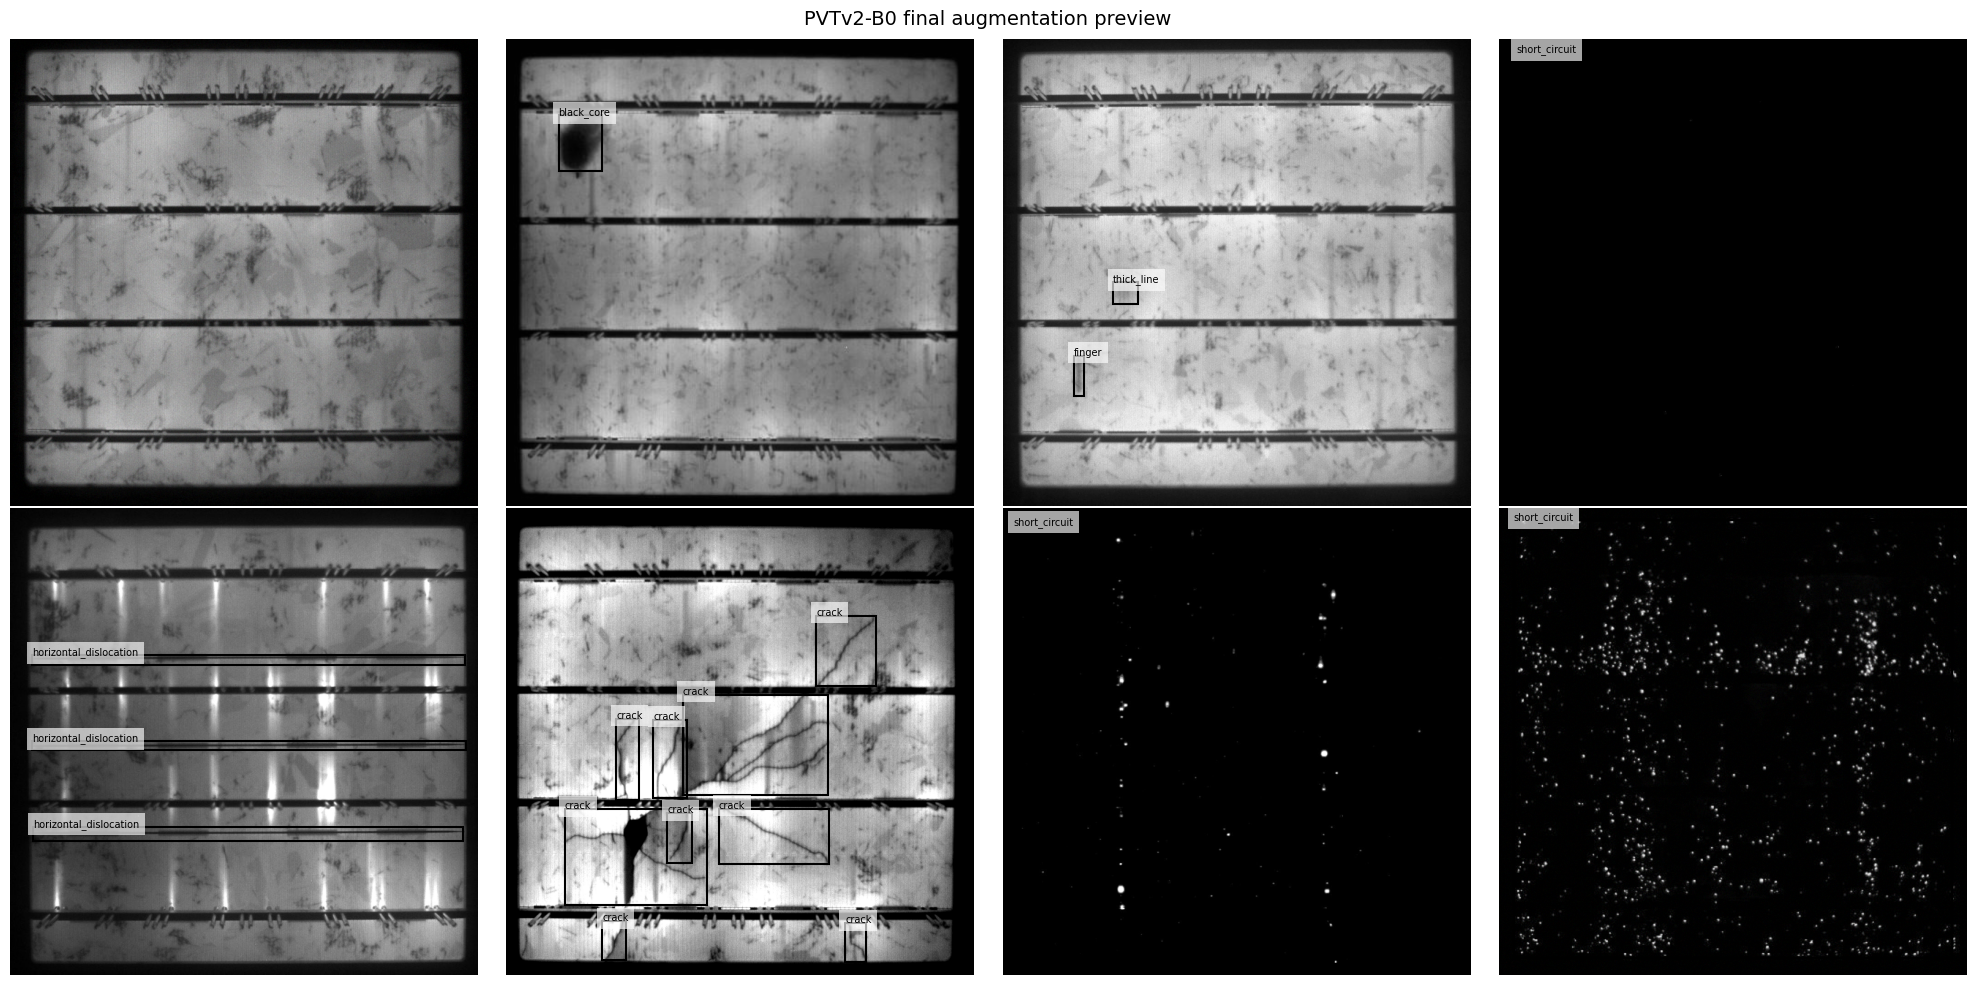

RNGs reset after preflight.


In [ ]:
from matplotlib.patches import Rectangle

def augmentation_preflight(
    dataset,
    sample_count=1000,
):
    selector = random.Random(SEED)

    indices = [
        selector.randrange(
            len(dataset)
        )
        for _ in range(sample_count)
    ]

    raw_counts = np.zeros(
        NUM_CLASSES,
        dtype=np.int64,
    )

    aug_counts = np.zeros(
        NUM_CLASSES,
        dtype=np.int64,
    )

    invalid = 0

    for idx in indices:
        (
            _,
            raw_boxes,
            raw_labels,
            _,
        ) = dataset._load_raw(idx)

        raw_counts += np.bincount(
            raw_labels,
            minlength=NUM_CLASSES,
        )

        image, target, _ = dataset[idx]

        boxes = (
            target["boxes"]
            .cpu()
            .numpy()
        )

        labels = (
            target["labels"]
            .cpu()
            .numpy()
        )

        aug_counts += np.bincount(
            labels,
            minlength=NUM_CLASSES,
        )

        if len(boxes) != len(raw_boxes):
            invalid += 1
            continue

        if len(boxes):
            if not np.isfinite(
                boxes
            ).all():
                invalid += 1
                continue

            if not (
                (
                    boxes[:, 2]
                    > boxes[:, 0]
                ).all()
                and (
                    boxes[:, 3]
                    > boxes[:, 1]
                ).all()
            ):
                invalid += 1

    print("=" * 70)
    print("AUGMENTATION PREFLIGHT")
    print("=" * 70)
    print(
        "Samples checked:",
        sample_count,
    )
    print(
        "Invalid samples:",
        invalid,
    )

    if invalid != 0:
        raise RuntimeError(
            "Augmentation preflight failed. "
            "Do NOT start training."
        )

    print(
        "\nClass-wise annotation retention:"
    )

    for cls_id, name in enumerate(
        CLASS_NAMES
    ):
        raw_n = int(
            raw_counts[cls_id]
        )

        aug_n = int(
            aug_counts[cls_id]
        )

        if raw_n == 0:
            print(
                f"{name:25s}: "
                "not sampled"
            )
            continue

        print(
            f"{name:25s}: "
            f"{aug_n}/{raw_n} "
            f"({aug_n/raw_n:.1%})"
        )

        if aug_n != raw_n:
            raise RuntimeError(
                f"Annotation count changed "
                f"for {name}. "
                "Do NOT train."
            )

    print(
        "\nPreflight PASSED."
    )


augmentation_preflight(
    train_dataset,
    sample_count=1000,
)


fig, axes = plt.subplots(
    2,
    4,
    figsize=(20, 10),
)

axes = axes.ravel()

preview_rng = random.Random(
    SEED + 1
)

for ax in axes:
    idx = preview_rng.randrange(
        len(train_dataset)
    )

    image, target, _ = (
        train_dataset[idx]
    )

    ax.imshow(
        image
        .permute(1, 2, 0)
        .cpu()
        .numpy()
        .clip(0, 1)
    )

    for box, cls_id in zip(
        target["boxes"].numpy(),
        target["labels"].numpy(),
    ):
        x1, y1, x2, y2 = box

        ax.add_patch(
            Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                linewidth=1.5,
            )
        )

        ax.text(
            x1,
            max(10, y1),
            CLASS_NAMES[
                int(cls_id)
            ],
            fontsize=7,
            bbox=dict(
                facecolor="white",
                alpha=0.65,
                edgecolor="none",
            ),
        )

    ax.axis("off")

plt.suptitle(
    "PVTv2-B0 final augmentation preview",
    fontsize=14,
)

plt.tight_layout()
plt.show()

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print(
    "RNGs reset after preflight."
)

## 10. Build PVTv2-B0 + deep Mamba + FPN + RetinaNet

The first two selected PVT feature levels pass directly to the FPN.

Only the deepest selected feature is converted from:

`[B, C, H, W] → [B, H×W, C]`

and processed by Mamba.

For better image context, the same Mamba module processes:
1. the forward flattened sequence,
2. the reversed sequence.

Their outputs are averaged, reversed back where necessary, then added through
a learnable residual gate.

The residual gate starts at `0.0`, so before fine-tuning the A1 detector is
functionally initialized from A0 rather than being immediately disrupted by a
randomly initialized Mamba branch.

In [ ]:
class DeepBidirectionalMamba(
    nn.Module
):
    def __init__(
        self,
        channels,
        d_state=16,
        d_conv=4,
        expand=2,
        gate_init=0.0,
    ):
        super().__init__()

        self.channels = channels

        self.norm = nn.LayerNorm(
            channels
        )

        self.mamba = Mamba(
            d_model=channels,
            d_state=d_state,
            d_conv=d_conv,
            expand=expand,
        )

        # Scalar residual gate.
        # tanh(0)=0 -> exact A0 path at initialization.
        self.gate = nn.Parameter(
            torch.tensor(
                float(gate_init)
            )
        )

    def forward(
        self,
        x,
    ):
        # x: [B, C, H, W]
        b, c, h, w = x.shape

        if c != self.channels:
            raise RuntimeError(
                f"Mamba expected {self.channels} channels, "
                f"received {c}."
            )

        # Raster-scan tokens:
        # [B,C,H,W] -> [B,H*W,C]
        seq = (
            x
            .flatten(2)
            .transpose(1, 2)
            .contiguous()
        )

        z = self.norm(
            seq
        )

        # Forward selective scan.
        y_forward = self.mamba(
            z
        )

        # Reverse scan using the SAME Mamba parameters.
        z_reverse = torch.flip(
            z,
            dims=[1],
        )

        y_reverse = self.mamba(
            z_reverse
        )

        y_reverse = torch.flip(
            y_reverse,
            dims=[1],
        )

        y = (
            y_forward
            + y_reverse
        ) * 0.5

        # Stable residual injection.
        seq = (
            seq
            + torch.tanh(
                self.gate
            ) * y
        )

        out = (
            seq
            .transpose(1, 2)
            .reshape(
                b,
                c,
                h,
                w,
            )
            .contiguous()
        )

        return out


class PVTv2B0MambaFPN(
    nn.Module
):
    def __init__(
        self,
        pretrained=False,
        out_channels=256,
    ):
        super().__init__()

        self.body = timm.create_model(
            "pvt_v2_b0",
            pretrained=pretrained,
            features_only=True,
            out_indices=(1, 2, 3),
        )

        feature_channels = (
            self.body
            .feature_info
            .channels()
        )

        feature_reductions = (
            self.body
            .feature_info
            .reduction()
        )

        print(
            "PVTv2 feature channels:",
            feature_channels,
        )

        print(
            "PVTv2 feature strides :",
            feature_reductions,
        )

        deepest_channels = (
            feature_channels[-1]
        )

        if deepest_channels != 256:
            raise RuntimeError(
                "Expected deepest PVTv2-B0 selected "
                f"feature to have 256 channels, got "
                f"{deepest_channels}."
            )

        self.deep_mamba = (
            DeepBidirectionalMamba(
                channels=deepest_channels,
                d_state=MAMBA_CONFIG[
                    "d_state"
                ],
                d_conv=MAMBA_CONFIG[
                    "d_conv"
                ],
                expand=MAMBA_CONFIG[
                    "expand"
                ],
                gate_init=MAMBA_CONFIG[
                    "residual_gate_init"
                ],
            )
        )

        self.fpn = (
            FeaturePyramidNetwork(
                in_channels_list=
                    feature_channels,

                out_channels=
                    out_channels,

                extra_blocks=
                    LastLevelP6P7(
                        feature_channels[-1],
                        out_channels,
                    ),
            )
        )

        self.out_channels = (
            out_channels
        )

    def forward(
        self,
        x,
    ):
        features = self.body(
            x
        )

        # Apply Mamba ONLY to deepest feature.
        features[-1] = (
            self.deep_mamba(
                features[-1]
            )
        )

        features = OrderedDict(
            (
                str(i),
                feat,
            )
            for i, feat
            in enumerate(features)
        )

        return self.fpn(
            features
        )


def build_model():
    backbone = (
        PVTv2B0MambaFPN(
            pretrained=False,
            out_channels=256,
        )
    )

    model = RetinaNet(
        backbone=backbone,
        num_classes=NUM_CLASSES,
        min_size=IMAGE_SIZE,
        max_size=IMAGE_SIZE,
        image_mean=[
            0.485,
            0.456,
            0.406,
        ],
        image_std=[
            0.229,
            0.224,
            0.225,
        ],
        score_thresh=0.001,
        detections_per_img=100,
    )

    return model


model = build_model()


# ------------------------------------------------------------
# Load all compatible A0 detector weights.
# Only the new deep_mamba parameters are allowed to be missing.
# ------------------------------------------------------------
a0_checkpoint = torch.load(
    A0_BEST_PT,
    map_location="cpu",
)

a0_state = (
    a0_checkpoint[
        "model_state"
    ]
)

load_result = (
    model.load_state_dict(
        a0_state,
        strict=False,
    )
)

missing_keys = list(
    load_result.missing_keys
)

unexpected_keys = list(
    load_result.unexpected_keys
)

bad_missing = [
    key
    for key in missing_keys
    if not key.startswith(
        "backbone.deep_mamba."
    )
]

if bad_missing:
    raise RuntimeError(
        "Unexpected missing non-Mamba weights "
        f"when loading A0: {bad_missing[:10]}"
    )

if unexpected_keys:
    raise RuntimeError(
        "Unexpected A0 checkpoint keys: "
        f"{unexpected_keys[:10]}"
    )

print(
    f"Loaded A0 checkpoint from epoch "
    f"{a0_checkpoint.get('epoch', 'unknown')}"
)

print(
    "A0 validation mAP50-95 stored in checkpoint:",
    a0_checkpoint.get(
        "best_map50_95",
        "not stored",
    ),
)

print(
    "New Mamba-only keys:",
    len(missing_keys),
)

print(
    "Unexpected checkpoint keys:",
    len(unexpected_keys),
)

# A0 transfer verified above. To reduce Google Drive usage,
# this notebook does NOT save a duplicate full initial checkpoint.
model = model.to(
    DEVICE
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

mamba_params = sum(
    p.numel()
    for p
    in model.backbone.deep_mamba.parameters()
)

print(
    f"Total parameters     : "
    f"{total_params:,} "
    f"({total_params/1e6:.3f} M)"
)

print(
    f"Trainable parameters : "
    f"{trainable_params:,} "
    f"({trainable_params/1e6:.3f} M)"
)

print(
    f"Mamba parameters     : "
    f"{mamba_params:,} "
    f"({mamba_params/1e6:.3f} M)"
)

print(
    "Initial Mamba residual gate:",
    float(
        model.backbone
        .deep_mamba
        .gate
        .detach()
        .cpu()
    ),
)


# ------------------------------------------------------------
# Deep-feature shape sanity test.
# ------------------------------------------------------------
model.eval()

with torch.no_grad():
    dummy = torch.zeros(
        1,
        3,
        IMAGE_SIZE,
        IMAGE_SIZE,
        device=DEVICE,
    )

    deep_features = (
        model.backbone.body(
            dummy
        )
    )

    deep = (
        deep_features[-1]
    )

print(
    "Deep feature shape:",
    tuple(deep.shape),
)

print(
    "Mamba sequence length:",
    deep.shape[-2]
    * deep.shape[-1],
)

del dummy
del deep_features
del deep

gc.collect()
torch.cuda.empty_cache()

PVTv2 feature channels: [64, 160, 256]
PVTv2 feature strides : [8, 16, 32]
Loaded A0 checkpoint from epoch 18
A0 validation mAP50-95 stored in checkpoint: 0.5764592289924622
New Mamba-only keys: 12
Unexpected checkpoint keys: 0
Total parameters     : 11,912,406 (11.912 M)
Trainable parameters : 11,912,406 (11.912 M)
Mamba parameters     : 438,273 (0.438 M)
Initial Mamba residual gate: 0.0
Deep feature shape: (1, 256, 20, 20)
Mamba sequence length: 400


## 11. Optimizer, differential learning rates and AMP

A1 is a fine-tuning experiment, not a full retraining from ImageNet.

Learning rates:
- existing PVT body: `1e-5`
- existing FPN + RetinaNet head: `5e-5`
- new Mamba block: `1e-4`

This lets the new module adapt quickly while protecting the already-good A0
representation.

In [ ]:
pvt_body_params = list(
    model.backbone
    .body
    .parameters()
)

mamba_params_list = list(
    model.backbone
    .deep_mamba
    .parameters()
)

fpn_head_params = (
    list(
        model.backbone
        .fpn
        .parameters()
    )
    + list(
        model.head
        .parameters()
    )
)

# Verify parameter groups are disjoint.
all_group_ids = (
    [id(p) for p in pvt_body_params]
    + [id(p) for p in fpn_head_params]
    + [id(p) for p in mamba_params_list]
)

if (
    len(all_group_ids)
    != len(set(all_group_ids))
):
    raise RuntimeError(
        "Optimizer parameter groups overlap."
    )

grouped_ids = set(
    all_group_ids
)

trainable_ids = {
    id(p)
    for p in model.parameters()
    if p.requires_grad
}

missing_from_optimizer = (
    trainable_ids
    - grouped_ids
)

if missing_from_optimizer:
    raise RuntimeError(
        f"{len(missing_from_optimizer)} trainable "
        "parameters were not assigned to the optimizer."
    )

optimizer = torch.optim.AdamW(
    [
        {
            "params":
                pvt_body_params,
            "lr":
                LR_PVT_BODY,
            "name":
                "pvt_body",
        },

        {
            "params":
                fpn_head_params,
            "lr":
                LR_FPN_HEAD,
            "name":
                "fpn_retinanet",
        },

        {
            "params":
                mamba_params_list,
            "lr":
                LR_MAMBA,
            "name":
                "mamba",
        },
    ],
    weight_decay=WEIGHT_DECAY,
)

scheduler = (
    torch.optim.lr_scheduler
    .CosineAnnealingLR(
        optimizer,
        T_max=MAX_EPOCHS,
        eta_min=1e-6,
    )
)

try:
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=AMP,
    )
except TypeError:
    scaler = (
        torch.cuda.amp
        .GradScaler(
            enabled=AMP,
        )
    )


def autocast_context():
    try:
        return torch.amp.autocast(
            "cuda",
            enabled=AMP,
        )
    except TypeError:
        return torch.cuda.amp.autocast(
            enabled=AMP,
        )


print(
    "Optimizer: AdamW"
)

for group in optimizer.param_groups:
    print(
        group.get(
            "name",
            "unnamed"
        ),
        "LR =",
        group["lr"],
    )

print(
    "AMP:",
    AMP,
)

Optimizer: AdamW
pvt_body LR = 1e-05
fpn_retinanet LR = 5e-05
mamba LR = 0.0001
AMP: True


## 12. Validation helpers

In [ ]:
def move_targets_to_device(targets):
    return [
        {
            k: v.to(
                DEVICE,
                non_blocking=True,
            )
            for k, v in t.items()
        }
        for t in targets
    ]


@torch.no_grad()
def compute_validation_loss(model, loader):
    # Torchvision detection models return losses in train mode.
    # PVTv2-B0 in timm has no random augmentation here;
    # gradients remain disabled by @torch.no_grad().
    model.train()

    total_cls = 0.0
    total_box = 0.0
    total_images = 0

    start = time.perf_counter()

    for images, targets, _ in loader:
        images = [
            img.to(
                DEVICE,
                non_blocking=True,
            )
            for img in images
        ]

        targets = move_targets_to_device(targets)

        with autocast_context():
            losses = model(
                images,
                targets,
            )

        batch_n = len(images)

        total_cls += (
            float(
                losses["classification"].detach()
            )
            * batch_n
        )

        total_box += (
            float(
                losses["bbox_regression"].detach()
            )
            * batch_n
        )

        total_images += batch_n

    torch.cuda.synchronize()

    seconds = (
        time.perf_counter()
        - start
    )

    model.eval()

    cls_loss = (
        total_cls
        / max(total_images, 1)
    )

    box_loss = (
        total_box
        / max(total_images, 1)
    )

    return {
        "classification_loss": cls_loss,
        "bbox_regression_loss": box_loss,
        "total_loss": cls_loss + box_loss,
        "seconds": seconds,
    }


@torch.no_grad()
def evaluate_map(model, loader):
    model.eval()

    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox",
        class_metrics=False,
    )

    start = time.perf_counter()

    for images, targets, _ in loader:
        images_gpu = [
            img.to(
                DEVICE,
                non_blocking=True,
            )
            for img in images
        ]

        with autocast_context():
            outputs = model(images_gpu)

        preds = [
            {
                "boxes": out["boxes"].detach().cpu(),
                "scores": out["scores"].detach().cpu(),
                "labels": out["labels"].detach().cpu(),
            }
            for out in outputs
        ]

        gts = [
            {
                "boxes": t["boxes"].detach().cpu(),
                "labels": t["labels"].detach().cpu(),
            }
            for t in targets
        ]

        metric.update(preds, gts)

    torch.cuda.synchronize()

    seconds = (
        time.perf_counter()
        - start
    )

    result = metric.compute()

    return {
        "map50": float(result["map_50"]),
        "map75": float(result["map_75"]),
        "map50_95": float(result["map"]),
        "seconds": seconds,
    }

# Fresh A1 start or resume

## 13. Resume support

For a brand-new A1 run:

```python
RESUME = False
```

If Colab disconnects after at least one completed A1 epoch:
1. reconnect to GPU,
2. rerun setup/model/optimizer cells,
3. set `RESUME = True`,
4. rerun this cell and the training cell.

`last.pt` belongs only to the A1 Mamba experiment.

In [ ]:
history = []
start_epoch = 1

best_map = -1.0
best_epoch = 0
epochs_without_improvement = 0

if RESUME:
    if not LAST_PT.exists():
        raise FileNotFoundError(
            f"No resume checkpoint found: {LAST_PT}"
        )

    checkpoint = torch.load(
        LAST_PT,
        map_location=DEVICE,
    )

    model.load_state_dict(
        checkpoint["model_state"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state"]
    )

    scheduler.load_state_dict(
        checkpoint["scheduler_state"]
    )

    if "scaler_state" in checkpoint:
        scaler.load_state_dict(
            checkpoint["scaler_state"]
        )

    start_epoch = (
        int(checkpoint["epoch"])
        + 1
    )

    best_map = float(
        checkpoint["best_map"]
    )

    best_epoch = int(
        checkpoint["best_epoch"]
    )

    epochs_without_improvement = int(
        checkpoint[
            "epochs_without_improvement"
        ]
    )

    history = checkpoint.get(
        "history",
        [],
    )

    print(
        f"Resuming from epoch "
        f"{start_epoch}"
    )

else:
    if LAST_PT.exists():
        raise RuntimeError(
            "Existing last.pt found. "
            "Set RESUME=True to continue, "
            "or delete/use a new experiment folder "
            "for a fresh run."
        )

    print(
        "Starting a fresh A1 "
        "PVTv2-B0 + Mamba + RetinaNet Aug run."
    )

Starting a fresh A1 PVTv2-B0 + Mamba + RetinaNet Aug run.


### 12.1 A0-transfer sanity check

For a fresh run only, this evaluates A1 **before fine-tuning**.

Because the Mamba residual gate is initialized to zero, the initial
predictions should be effectively the transferred A0 detector.

This check does not use the test set.

In [ ]:
if not RESUME:
    print(
        "Checking transferred A0 model on validation set..."
    )

    initial_val = evaluate_map(
        model,
        val_loader,
    )

    initial_val_df = pd.DataFrame([
        {
            "source_A0_checkpoint":
                str(A0_BEST_PT),

            "stored_A0_val_mAP50-95":
                a0_checkpoint.get(
                    "best_map50_95",
                    np.nan,
                ),

            "A1_initial_val_mAP50":
                initial_val[
                    "map50"
                ],

            "A1_initial_val_mAP75":
                initial_val[
                    "map75"
                ],

            "A1_initial_val_mAP50-95":
                initial_val[
                    "map50_95"
                ],

            "initial_mamba_gate":
                float(
                    model.backbone
                    .deep_mamba
                    .gate
                    .detach()
                    .cpu()
                ),
        }
    ])

    initial_val_df.to_csv(
        METRICS_DIR
        / "initial_transfer_validation.csv",
        index=False,
    )

    display(
        initial_val_df
    )

    stored_a0 = (
        a0_checkpoint.get(
            "best_map50_95"
        )
    )

    if stored_a0 is not None:
        difference = abs(
            initial_val[
                "map50_95"
            ]
            - float(stored_a0)
        )

        print(
            "Absolute difference from stored "
            f"A0 val mAP50-95: {difference:.6f}"
        )

        if difference > 0.002:
            warnings.warn(
                "Initial A1 validation metric differs "
                "from the stored A0 metric by >0.002. "
                "Check transfer/loading before training."
            )

    # Reset RNGs so the audit does not change training randomness.
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    print(
        "RNGs reset after transfer sanity check."
    )
else:
    print(
        "Resume mode: initial A0-transfer check skipped."
    )

Checking transferred A0 model on validation set...


,source_A0_checkpoint,stored_A0_val_mAP50-95,A1_initial_val_mAP50,A1_initial_val_mAP75,A1_initial_val_mAP50-95,initial_mamba_gate
0,/content/drive/MyDrive/Study Materials /CSE465...,0.576459,0.91565,0.566825,0.576459,0.0


Absolute difference from stored A0 val mAP50-95: 0.000000
RNGs reset after transfer sanity check.


## 13. Train — live epoch/batch progress

The model is selected using validation **mAP@50-95**.

Early stopping:
- maximum = 50 epochs
- patience = 5

The live progress bar shows current batch loss and VRAM.

In [ ]:
from tqdm.auto import tqdm

for epoch in range(
    start_epoch,
    MAX_EPOCHS + 1,
):

    model.train()

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    epoch_start = time.perf_counter()

    train_cls_sum = 0.0
    train_box_sum = 0.0
    train_images = 0

    optimizer.zero_grad(
        set_to_none=True
    )

    n_steps = len(train_loader)

    train_bar = tqdm(
        enumerate(train_loader),
        total=n_steps,
        desc=f"Epoch {epoch}/{MAX_EPOCHS}",
        dynamic_ncols=True,
    )

    for step, (
        images,
        targets,
        _,
    ) in train_bar:

        images = [
            img.to(
                DEVICE,
                non_blocking=True,
            )
            for img in images
        ]

        targets = move_targets_to_device(
            targets
        )

        group_start = (
            step // ACCUM_STEPS
        ) * ACCUM_STEPS

        group_end = min(
            group_start + ACCUM_STEPS,
            n_steps,
        )

        group_size = (
            group_end - group_start
        )

        with autocast_context():
            losses = model(
                images,
                targets,
            )

            cls_loss = losses[
                "classification"
            ]

            box_loss = losses[
                "bbox_regression"
            ]

            total_loss = (
                cls_loss + box_loss
            )

            if not torch.isfinite(
                total_loss
            ):
                raise RuntimeError(
                    f"Non-finite training loss at "
                    f"epoch {epoch}, step {step}. "
                    "Training stopped immediately."
                )

            scaled_loss = (
                total_loss
                / group_size
            )

        scaler.scale(
            scaled_loss
        ).backward()

        if step == group_end - 1:
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRAD_CLIP,
            )

            scaler.step(optimizer)
            scaler.update()

            optimizer.zero_grad(
                set_to_none=True
            )

        batch_n = len(images)

        train_cls_sum += (
            float(cls_loss.detach())
            * batch_n
        )

        train_box_sum += (
            float(box_loss.detach())
            * batch_n
        )

        train_images += batch_n

        train_bar.set_postfix({
            "loss": (
                f"{float(total_loss.detach()):.4f}"
            ),
            "cls": (
                f"{float(cls_loss.detach()):.4f}"
            ),
            "box": (
                f"{float(box_loss.detach()):.4f}"
            ),
            "VRAM": (
                f"{torch.cuda.memory_allocated()/1024**3:.1f}G"
            ),
        })

    torch.cuda.synchronize()

    train_seconds = (
        time.perf_counter()
        - epoch_start
    )

    train_cls = (
        train_cls_sum
        / train_images
    )

    train_box = (
        train_box_sum
        / train_images
    )

    train_total = (
        train_cls + train_box
    )

    print(
        "\nCalculating validation loss..."
    )

    val_loss_result = (
        compute_validation_loss(
            model,
            val_loader,
        )
    )

    print(
        "Calculating validation mAP..."
    )

    val_map_result = evaluate_map(
        model,
        val_loader,
    )

    scheduler.step()

    total_seconds = (
        train_seconds
        + val_loss_result["seconds"]
        + val_map_result["seconds"]
    )

    peak_vram_gb = (
        torch.cuda.max_memory_allocated()
        / 1024**3
    )

    record = {
        "epoch": epoch,

        "train/classification_loss":
            train_cls,

        "train/bbox_regression_loss":
            train_box,

        "train/total_loss":
            train_total,

        "val/classification_loss":
            val_loss_result[
                "classification_loss"
            ],

        "val/bbox_regression_loss":
            val_loss_result[
                "bbox_regression_loss"
            ],

        "val/total_loss":
            val_loss_result[
                "total_loss"
            ],

        "val/mAP50":
            val_map_result["map50"],

        "val/mAP75":
            val_map_result["map75"],

        "val/mAP50-95":
            val_map_result["map50_95"],

        "train_seconds":
            train_seconds,

        "val_loss_seconds":
            val_loss_result["seconds"],

        "val_map_seconds":
            val_map_result["seconds"],

        "total_seconds":
            total_seconds,

        "lr":
            optimizer.param_groups[0]["lr"],

        "lr_pvt_body":
            optimizer.param_groups[0]["lr"],

        "lr_fpn_head":
            optimizer.param_groups[1]["lr"],

        "lr_mamba":
            optimizer.param_groups[2]["lr"],

        "mamba_gate":
            float(
                model.backbone
                .deep_mamba
                .gate
                .detach()
                .cpu()
            ),

        "peak_vram_GB":
            peak_vram_gb,
    }

    history.append(record)

    history_df = pd.DataFrame(
        history
    )

    history_df.to_csv(
        METRICS_DIR
        / "training_history.csv",
        index=False,
    )

    current_map = (
        val_map_result["map50_95"]
    )

    if (
        not np.isfinite(current_map)
        or current_map < 0
    ):
        raise RuntimeError(
            f"Invalid validation mAP50-95 "
            f"at epoch {epoch}: {current_map}. "
            "Checkpoint remains available from the "
            "previous completed epoch."
        )

    improved = (
        current_map > best_map
    )

    if improved:
        best_map = current_map
        best_epoch = epoch

        epochs_without_improvement = 0

        best_state = {
            "epoch": epoch,
            "best_map50_95": best_map,

            "model_state": {
                k: v.detach().cpu()
                for k, v
                in model.state_dict().items()
            },

            "class_names": CLASS_NAMES,
            "training_config":
                training_config,
        }

        torch.save(
            best_state,
            BEST_PT,
        )

    else:
        epochs_without_improvement += 1

    last_state = {
        "epoch": epoch,

        "model_state":
            model.state_dict(),

        "optimizer_state":
            optimizer.state_dict(),

        "scheduler_state":
            scheduler.state_dict(),

        "scaler_state":
            scaler.state_dict(),

        "best_map":
            best_map,

        "best_epoch":
            best_epoch,

        "epochs_without_improvement":
            epochs_without_improvement,

        "history":
            history,

        "training_config":
            training_config,
    }

    torch.save(
        last_state,
        LAST_PT,
    )

    print(
        "\n"
        + "=" * 70
    )

    print(
        f"EPOCH {epoch}/{MAX_EPOCHS} COMPLETE"
    )

    print("-" * 70)

    print(
        f"Train Loss    : "
        f"{train_total:.4f} "
        f"(Cls {train_cls:.4f} | "
        f"Box {train_box:.4f})"
    )

    print(
        f"Val Loss      : "
        f"{val_loss_result['total_loss']:.4f}"
    )

    print(
        f"Val mAP@50    : "
        f"{val_map_result['map50']:.4f}"
    )

    print(
        f"Val mAP@75    : "
        f"{val_map_result['map75']:.4f}"
    )

    print(
        f"Val mAP@50-95 : "
        f"{current_map:.4f}"
    )

    print("-" * 70)

    print(
        f"Train time    : "
        f"{train_seconds/60:.2f} min"
    )

    print(
        f"Val-loss time : "
        f"{val_loss_result['seconds']/60:.2f} min"
    )

    print(
        f"Val-mAP time  : "
        f"{val_map_result['seconds']/60:.2f} min"
    )

    print(
        f"Total epoch   : "
        f"{total_seconds/60:.2f} min"
    )

    print(
        f"Peak VRAM     : "
        f"{peak_vram_gb:.2f} GB"
    )

    print("-" * 70)

    print(
        f"Best epoch    : "
        f"{best_epoch}"
    )

    print(
        f"Best mAP50-95 : "
        f"{best_map:.4f}"
    )

    print(
        f"Early stopping: "
        f"{epochs_without_improvement}/{PATIENCE}"
    )

    print("=" * 70)

    if (
        epochs_without_improvement
        >= PATIENCE
    ):
        print(
            f"\nEarly stopping triggered "
            f"at epoch {epoch}."
        )

        break

print("\nTRAINING FINISHED")
print("Best epoch:", best_epoch)

print(
    "Best validation mAP@50-95:",
    round(best_map, 4),
)

Epoch 1/25:   0%|          | 0/553 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...

EPOCH 1/25 COMPLETE
----------------------------------------------------------------------
Train Loss    : 0.2499 (Cls 0.1271 | Box 0.1228)
Val Loss      : 0.7660
Val mAP@50    : 0.9165
Val mAP@75    : 0.5592
Val mAP@50-95 : 0.5702
----------------------------------------------------------------------
Train time    : 3.87 min
Val-loss time : 0.35 min
Val-mAP time  : 0.46 min
Total epoch   : 4.68 min
Peak VRAM     : 2.50 GB
----------------------------------------------------------------------
Best epoch    : 1
Best mAP50-95 : 0.5702
Early stopping: 0/5


Epoch 2/25:   0%|          | 0/553 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...

EPOCH 2/25 COMPLETE
----------------------------------------------------------------------
Train Loss    : 0.2121 (Cls 0.0960 | Box 0.1161)
Val Loss      : 1.0324
Val mAP@50    : 0.9325
Val mAP@75    : 0.5701
Val mAP@50-95 : 0.5982
----------------------------------------------------------------------
Train time    : 3.74 min
Val-loss time : 0.38 min
Val-mAP time  : 0.46 min
Total epoch   : 4.58 min
Peak VRAM     : 2.50 GB
----------------------------------------------------------------------
Best epoch    : 2
Best mAP50-95 : 0.5982
Early stopping: 0/5


Epoch 3/25:   0%|          | 0/553 [00:00<?, ?it/s]

...


Calculating validation loss...
Calculating validation mAP...

EPOCH 6/25 COMPLETE
----------------------------------------------------------------------
Train Loss    : 0.2013 (Cls 0.0939 | Box 0.1074)
Val Loss      : 0.6340
Val mAP@50    : 0.9331
Val mAP@75    : 0.6203
Val mAP@50-95 : 0.6031
----------------------------------------------------------------------
Train time    : 3.79 min
Val-loss time : 0.36 min
Val-mAP time  : 0.46 min
Total epoch   : 4.61 min
Peak VRAM     : 2.50 GB
----------------------------------------------------------------------
Best epoch    : 3
Best mAP50-95 : 0.6045
Early stopping: 3/5


Epoch 7/25:   0%|          | 0/553 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...

EPOCH 7/25 COMPLETE
----------------------------------------------------------------------
Train Loss    : 0.1948 (Cls 0.0905 | Box 0.1044)
Val Loss      : 0.6702
Val mAP@50    : 0.9101
Val mAP@75    : 0.5693
Val mAP@50-95 : 0.5704
----------------------------------------------------------------------
Train time    : 3.77 min
Val-loss time : 0.38 min
Val-mAP time  : 0.44 min
Total epoch   : 4.58 min
Peak VRAM     : 2.50 GB
----------------------------------------------------------------------
Best epoch    : 3
Best mAP50-95 : 0.6045
Early stopping: 4/5


Epoch 8/25:   0%|          | 0/553 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...

EPOCH 8/25 COMPLETE
----------------------------------------------------------------------
Train Loss    : 0.1841 (Cls 0.0812 | Box 0.1029)
Val Loss      : 0.9371
Val mAP@50    : 0.9270
Val mAP@75    : 0.5538
Val mAP@50-95 : 0.5901
----------------------------------------------------------------------
Train time    : 3.74 min
Val-loss time : 0.36 min
Val-mAP time  : 0.44 min
Total epoch   : 4.54 min
Peak VRAM     : 2.50 GB
----------------------------------------------------------------------
Best epoch    : 3
Best mAP50-95 : 0.6045
Early stopping: 5/5

Early stopping triggered at epoch 8.

TRAINING FINISHED
Best epoch: 3
Best validation mAP@50-95: 0.6045


# Result

## 14. Training history and timing summary

In [ ]:
history_df = pd.read_csv(
    METRICS_DIR
    / "training_history.csv"
)

epochs_completed = int(
    history_df["epoch"].max()
)

best_row = history_df.loc[
    history_df["val/mAP50-95"].idxmax()
]

best_epoch = int(
    best_row["epoch"]
)

timing_summary = pd.DataFrame([{
    "epochs_completed":
        epochs_completed,

    "best_epoch":
        best_epoch,

    "mean_train_min_per_epoch":
        history_df[
            "train_seconds"
        ].mean() / 60,

    "mean_val_loss_min_per_epoch":
        history_df[
            "val_loss_seconds"
        ].mean() / 60,

    "mean_val_map_min_per_epoch":
        history_df[
            "val_map_seconds"
        ].mean() / 60,

    "mean_total_min_per_epoch":
        history_df[
            "total_seconds"
        ].mean() / 60,

    "total_training_run_min":
        history_df[
            "total_seconds"
        ].sum() / 60,

    "mean_peak_vram_GB":
        history_df[
            "peak_vram_GB"
        ].mean(),

    "max_peak_vram_GB":
        history_df[
            "peak_vram_GB"
        ].max(),
}]).round(4)

timing_summary.to_csv(
    METRICS_DIR
    / "timing_summary.csv",
    index=False,
)

display(timing_summary)

,epochs_completed,best_epoch,mean_train_min_per_epoch,mean_val_loss_min_per_epoch,mean_val_map_min_per_epoch,mean_total_min_per_epoch,total_training_run_min,mean_peak_vram_GB,max_peak_vram_GB
0,8,3,3.7901,0.364,0.4571,4.6111,36.8889,2.5032,2.5047


## 15. Training vs validation loss curves

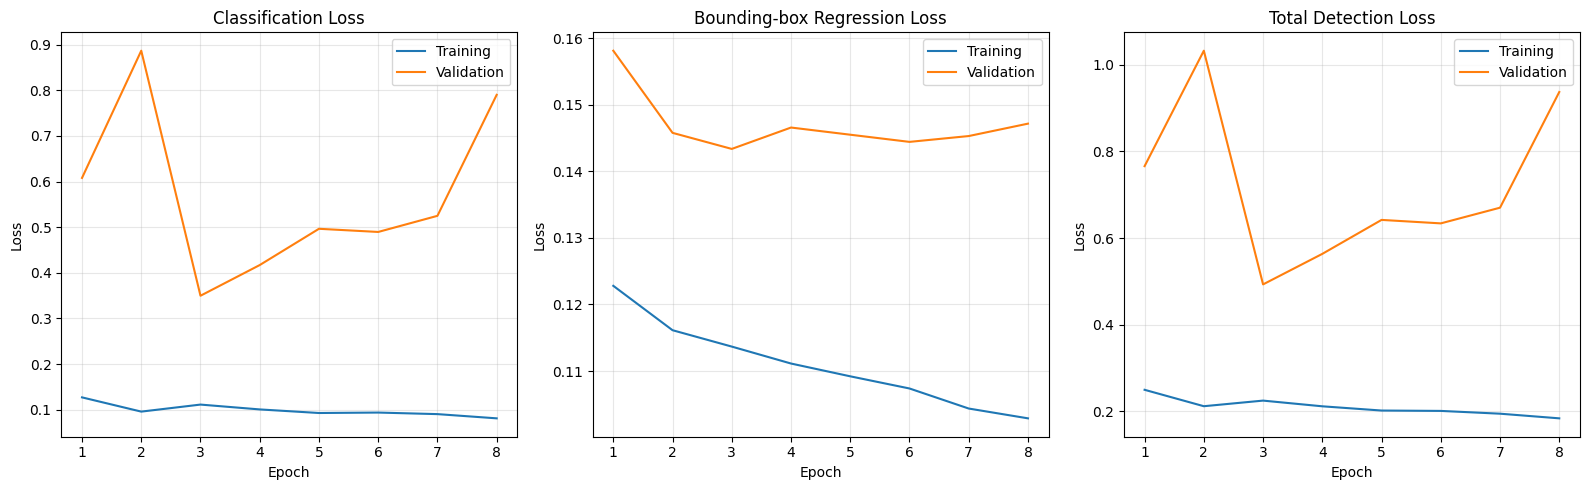

In [ ]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5),
)

loss_pairs = [
    (
        "train/classification_loss",
        "val/classification_loss",
        "Classification Loss",
    ),
    (
        "train/bbox_regression_loss",
        "val/bbox_regression_loss",
        "Bounding-box Regression Loss",
    ),
    (
        "train/total_loss",
        "val/total_loss",
        "Total Detection Loss",
    ),
]

for ax, (
    train_col,
    val_col,
    title,
) in zip(
    axes,
    loss_pairs,
):
    ax.plot(
        history_df["epoch"],
        history_df[train_col],
        label="Training",
    )

    ax.plot(
        history_df["epoch"],
        history_df[val_col],
        label="Validation",
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()

plt.savefig(
    PLOTS_DIR
    / "training_validation_loss_curves.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 16. Validation mAP vs epoch

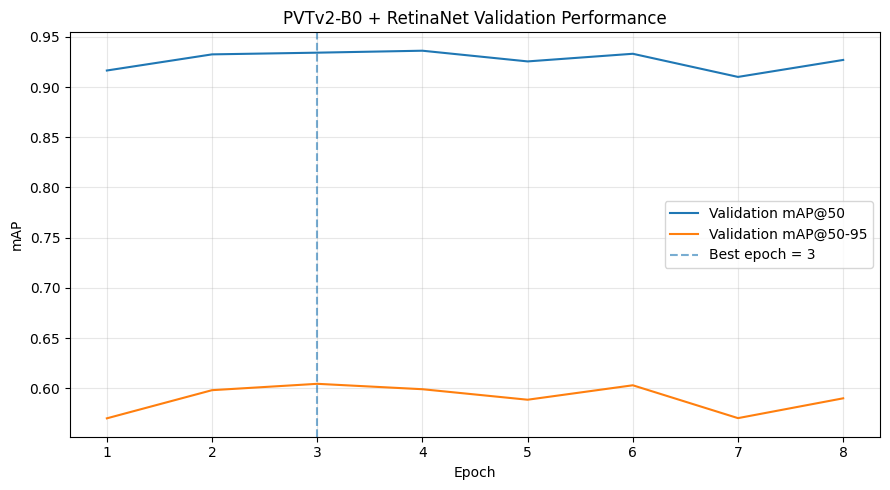

In [ ]:
plt.figure(
    figsize=(9, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["val/mAP50"],
    label="Validation mAP@50",
)

plt.plot(
    history_df["epoch"],
    history_df["val/mAP50-95"],
    label="Validation mAP@50-95",
)

plt.axvline(
    best_epoch,
    linestyle="--",
    alpha=0.6,
    label=f"Best epoch = {best_epoch}",
)

plt.xlabel("Epoch")
plt.ylabel("mAP")

plt.title(
    "PVTv2-B0 + RetinaNet "
    "Validation Performance"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    PLOTS_DIR
    / "validation_map_vs_epoch.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 17. Load the best model for final test evaluation

In [ ]:
best_checkpoint = torch.load(
    BEST_PT,
    map_location="cpu",
)

model.load_state_dict(
    best_checkpoint["model_state"]
)

model = model.to(DEVICE)
model.eval()

gc.collect()
torch.cuda.empty_cache()

print(
    f"Loaded best model from epoch "
    f"{best_checkpoint['epoch']} "
    f"(val mAP50-95="
    f"{best_checkpoint['best_map50_95']:.4f})"
)

Loaded best model from epoch 3 (val mAP50-95=0.6045)


## 18. Collect test predictions once

In [ ]:
@torch.no_grad()
def collect_predictions(
    model,
    loader,
):
    model.eval()

    predictions = []
    targets_all = []
    paths_all = []

    total_forward_seconds = 0.0
    total_images = 0

    for images, targets, paths in loader:
        images_gpu = [
            img.to(
                DEVICE,
                non_blocking=True,
            )
            for img in images
        ]

        torch.cuda.synchronize()
        start = time.perf_counter()

        with autocast_context():
            outputs = model(
                images_gpu
            )

        torch.cuda.synchronize()

        total_forward_seconds += (
            time.perf_counter()
            - start
        )

        total_images += len(images)

        for out in outputs:
            predictions.append({
                "boxes":
                    out["boxes"].detach().cpu(),

                "scores":
                    out["scores"].detach().cpu(),

                "labels":
                    out["labels"].detach().cpu(),
            })

        for target in targets:
            targets_all.append({
                "boxes":
                    target["boxes"].detach().cpu(),

                "labels":
                    target["labels"].detach().cpu(),
            })

        paths_all.extend(paths)

    inference_ms = (
        total_forward_seconds
        / max(total_images, 1)
        * 1000
    )

    return (
        predictions,
        targets_all,
        paths_all,
        inference_ms,
    )


(
    test_predictions,
    test_targets,
    test_paths,
    inference_ms,
) = collect_predictions(
    model,
    test_loader,
)

fps = (
    1000 / inference_ms
    if inference_ms > 0
    else np.nan
)

print(
    "Test images:",
    len(test_predictions),
)

print(
    f"Model forward time: "
    f"{inference_ms:.3f} ms/image"
)

print(
    f"FPS: {fps:.2f}"
)

Test images: 949
Model forward time: 31.024 ms/image
FPS: 32.23


## 19. Test mAP50, mAP75 and mAP50–95

In [ ]:
map_metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    class_metrics=True,
)

map50_metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    iou_thresholds=[0.50],
    class_metrics=True,
)

map_metric.update(
    test_predictions,
    test_targets,
)

map50_metric.update(
    test_predictions,
    test_targets,
)

map_result = (
    map_metric.compute()
)

map50_result = (
    map50_metric.compute()
)

test_map50 = float(
    map_result["map_50"]
)

test_map75 = float(
    map_result["map_75"]
)

test_map50_95 = float(
    map_result["map"]
)

print(
    f"mAP@50    : "
    f"{test_map50:.4f}"
)

print(
    f"mAP@75    : "
    f"{test_map75:.4f}"
)

print(
    f"mAP@50-95 : "
    f"{test_map50_95:.4f}"
)

mAP@50    : 0.9036
mAP@75    : 0.5953
mAP@50-95 : 0.5906


## 20. Precision, Recall, F1, matched box IoU and Dice

Threshold metrics:
- confidence ≥ 0.25
- class-aware one-to-one matching
- TP IoU threshold = 0.50

IoU and Dice are **bounding-box overlap metrics**, not segmentation-mask metrics.

In [ ]:
def class_aware_matches(
    pred,
    gt,
    conf_threshold=0.25,
    iou_threshold=0.50,
):
    keep = (
        pred["scores"]
        >= conf_threshold
    )

    p_boxes = pred["boxes"][keep]
    p_labels = pred["labels"][keep]

    g_boxes = gt["boxes"]
    g_labels = gt["labels"]

    if (
        len(p_boxes) == 0
        or len(g_boxes) == 0
    ):
        return (
            [],
            p_boxes,
            p_labels,
        )

    ious = box_iou(
        p_boxes,
        g_boxes,
    )

    candidates = []

    for pi in range(
        len(p_boxes)
    ):
        for gi in range(
            len(g_boxes)
        ):
            if (
                int(p_labels[pi])
                != int(g_labels[gi])
            ):
                continue

            iou = float(
                ious[pi, gi]
            )

            if (
                iou
                >= iou_threshold
            ):
                candidates.append(
                    (
                        iou,
                        pi,
                        gi,
                    )
                )

    candidates.sort(
        reverse=True
    )

    used_pred = set()
    used_gt = set()
    matches = []

    for iou, pi, gi in candidates:
        if (
            pi in used_pred
            or gi in used_gt
        ):
            continue

        used_pred.add(pi)
        used_gt.add(gi)

        matches.append(
            (
                pi,
                gi,
                iou,
            )
        )

    return (
        matches,
        p_boxes,
        p_labels,
    )


overall_tp = 0
overall_fp = 0
overall_fn = 0

matched_ious = []

per_class_counts = defaultdict(
    lambda: {
        "tp": 0,
        "fp": 0,
        "fn": 0,
        "ious": [],
    }
)

for pred, gt in zip(
    test_predictions,
    test_targets,
):
    (
        matches,
        p_boxes,
        p_labels,
    ) = class_aware_matches(
        pred,
        gt,
        CONF_THRESHOLD,
        MATCH_IOU_THRESHOLD,
    )

    matched_p = {
        m[0]
        for m in matches
    }

    matched_g = {
        m[1]
        for m in matches
    }

    tp = len(matches)
    fp = len(p_boxes) - tp
    fn = len(gt["boxes"]) - tp

    overall_tp += tp
    overall_fp += fp
    overall_fn += fn

    for (
        pi,
        gi,
        iou,
    ) in matches:
        cls_id = int(
            gt["labels"][gi]
        )

        matched_ious.append(
            iou
        )

        per_class_counts[
            cls_id
        ]["tp"] += 1

        per_class_counts[
            cls_id
        ]["ious"].append(
            iou
        )

    for pi, cls_id in enumerate(
        p_labels.tolist()
    ):
        if pi not in matched_p:
            per_class_counts[
                int(cls_id)
            ]["fp"] += 1

    for gi, cls_id in enumerate(
        gt["labels"].tolist()
    ):
        if gi not in matched_g:
            per_class_counts[
                int(cls_id)
            ]["fn"] += 1


test_precision = (
    overall_tp
    / (overall_tp + overall_fp)
    if (
        overall_tp + overall_fp
    )
    else 0.0
)

test_recall = (
    overall_tp
    / (overall_tp + overall_fn)
    if (
        overall_tp + overall_fn
    )
    else 0.0
)

test_f1 = (
    2
    * test_precision
    * test_recall
    / (
        test_precision
        + test_recall
    )
    if (
        test_precision
        + test_recall
    )
    else 0.0
)

mean_iou = (
    float(
        np.mean(matched_ious)
    )
    if matched_ious
    else np.nan
)

matched_dices = [
    2 * iou / (1 + iou)
    for iou in matched_ious
]

mean_dice = (
    float(
        np.mean(matched_dices)
    )
    if matched_dices
    else np.nan
)

print(
    f"Precision : "
    f"{test_precision:.4f}"
)

print(
    f"Recall    : "
    f"{test_recall:.4f}"
)

print(
    f"F1        : "
    f"{test_f1:.4f}"
)

print(
    f"TP / FP / FN: "
    f"{overall_tp} / "
    f"{overall_fp} / "
    f"{overall_fn}"
)

print(
    f"Mean matched box IoU : "
    f"{mean_iou:.4f}"
)

print(
    f"Mean matched box Dice: "
    f"{mean_dice:.4f}"
)

Precision : 0.7242
Recall    : 0.9194
F1        : 0.8102
TP / FP / FN: 1381 / 526 / 121
Mean matched box IoU : 0.8233
Mean matched box Dice: 0.8991


## 21. Per-class test performance

In [ ]:
map95_by_class = {}
map50_by_class = {}

classes95 = (
    map_result["classes"]
    .cpu()
    .numpy()
    .astype(int)
)

values95 = (
    map_result["map_per_class"]
    .cpu()
    .numpy()
)

for cls_id, value in zip(
    classes95,
    values95,
):
    map95_by_class[
        int(cls_id)
    ] = (
        float(value)
        if value >= 0
        else np.nan
    )

classes50 = (
    map50_result["classes"]
    .cpu()
    .numpy()
    .astype(int)
)

values50 = (
    map50_result["map_per_class"]
    .cpu()
    .numpy()
)

for cls_id, value in zip(
    classes50,
    values50,
):
    map50_by_class[
        int(cls_id)
    ] = (
        float(value)
        if value >= 0
        else np.nan
    )


class_image_counts = defaultdict(
    set
)

class_instance_counts = defaultdict(
    int
)

for image_idx, target in enumerate(
    test_targets
):
    for cls_id in target[
        "labels"
    ].tolist():
        class_image_counts[
            int(cls_id)
        ].add(image_idx)

        class_instance_counts[
            int(cls_id)
        ] += 1


rows = []

for cls_id, class_name in enumerate(
    CLASS_NAMES
):
    stats = per_class_counts[
        cls_id
    ]

    tp = stats["tp"]
    fp = stats["fp"]
    fn = stats["fn"]

    p = (
        tp / (tp + fp)
        if tp + fp
        else np.nan
    )

    r = (
        tp / (tp + fn)
        if tp + fn
        else np.nan
    )

    f1 = (
        2 * p * r / (p + r)
        if (
            np.isfinite(p)
            and np.isfinite(r)
            and p + r > 0
        )
        else np.nan
    )

    cls_iou = (
        float(
            np.mean(
                stats["ious"]
            )
        )
        if stats["ious"]
        else np.nan
    )

    cls_dice = (
        2
        * cls_iou
        / (1 + cls_iou)
        if np.isfinite(
            cls_iou
        )
        else np.nan
    )

    rows.append({
        "Class": class_name,
        "Images":
            len(
                class_image_counts[
                    cls_id
                ]
            ),
        "Instances":
            class_instance_counts[
                cls_id
            ],
        "Box-P": p,
        "Box-R": r,
        "Box-F1": f1,
        "mAP50":
            map50_by_class.get(
                cls_id,
                np.nan,
            ),
        "mAP50-95":
            map95_by_class.get(
                cls_id,
                np.nan,
            ),
        "Mean Box IoU":
            cls_iou,
        "Mean Box Dice":
            cls_dice,
    })


per_class_df = pd.DataFrame(
    rows
).round(4)

per_class_df.to_csv(
    METRICS_DIR
    / "final_per_class_summary.csv",
    index=False,
)

display(per_class_df)

,Class,Images,Instances,Box-P,Box-R,Box-F1,mAP50,mAP50-95,Mean Box IoU,Mean Box Dice
0,finger,187,385,0.7479,0.9091,0.8206,0.9112,0.4455,0.7600,0.8637
1,crack,185,231,0.5506,0.8009,0.6526,0.7224,0.4124,0.7860,0.8802
2,black_core,150,152,0.9351,0.9474,0.9412,0.9742,0.8905,0.9436,0.9710
3,thick_line,149,167,0.7581,0.8443,0.7989,0.8608,0.4329,0.7549,0.8603
4,horizontal_dislocation,119,357,1.0000,1.0000,1.0000,1.0000,0.6745,0.8517,0.9199
5,short_circuit,113,113,0.9244,0.9735,0.9483,0.9523,0.9308,0.9696,0.9846
6,vertical_dislocation,16,64,0.2712,1.0000,0.4267,0.9487,0.5083,0.7815,0.8773
7,star_crack,30,33,0.5882,0.9091,0.7143,0.8595,0.4297,0.7492,0.8566
8,printing_error,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 22. Raw and normalized confusion matrices

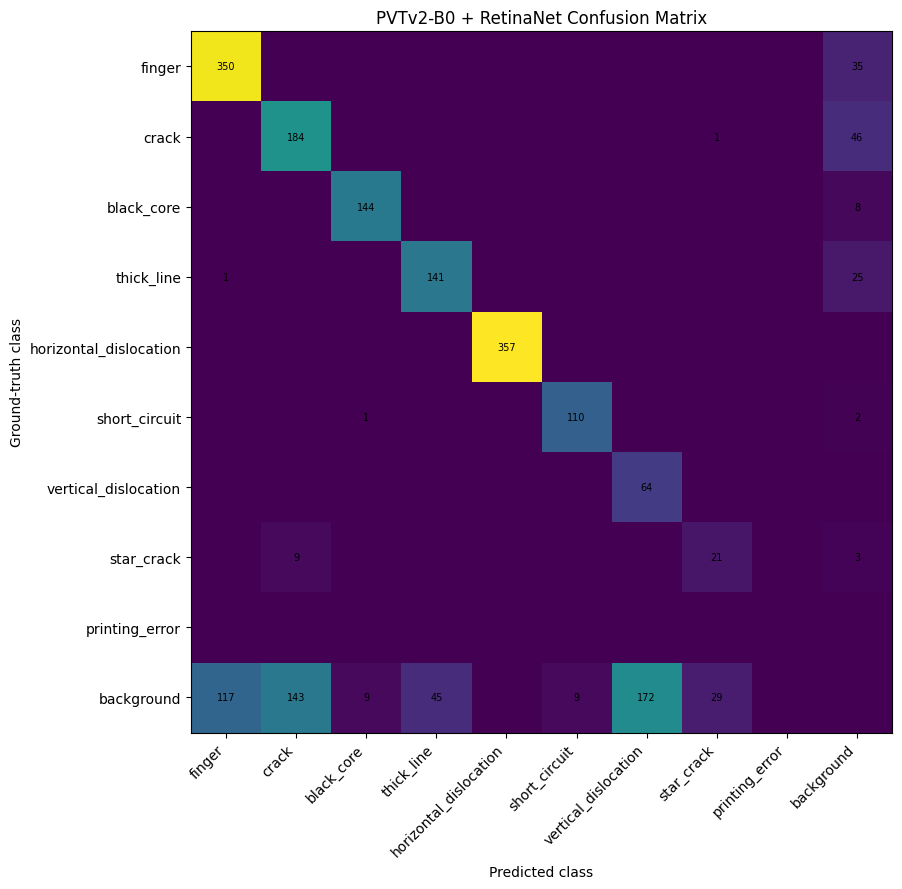

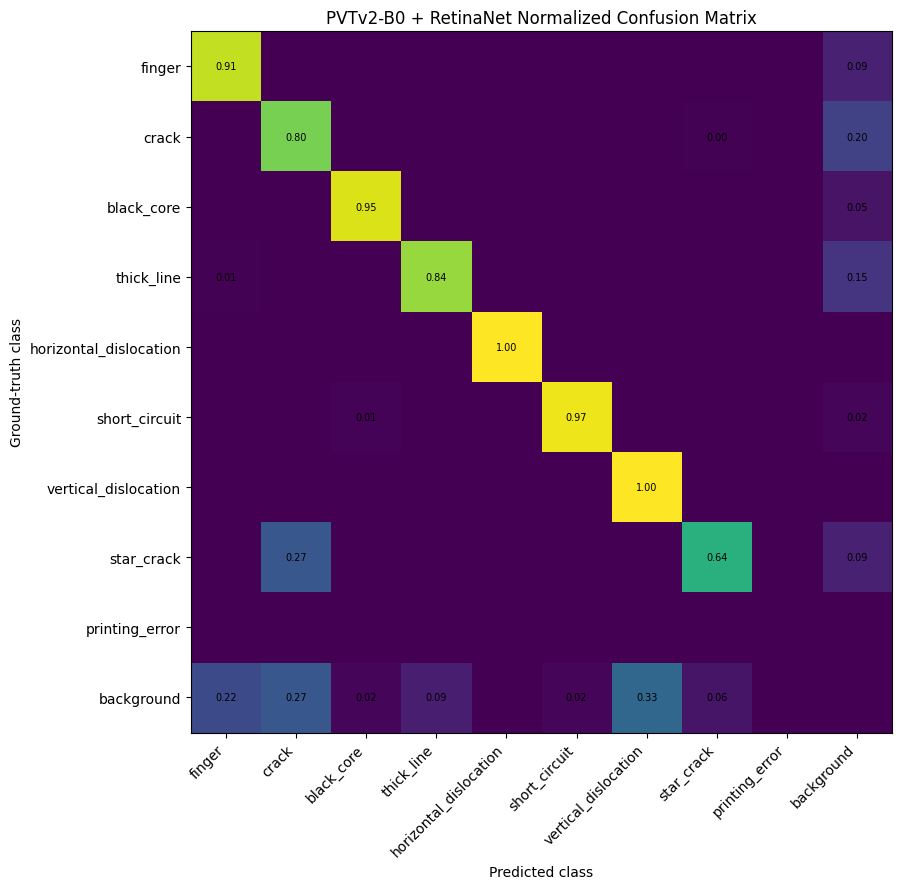

In [ ]:
N = NUM_CLASSES
BG = N

confusion = np.zeros(
    (N + 1, N + 1),
    dtype=np.int64,
)

for pred, gt in zip(
    test_predictions,
    test_targets,
):
    keep = (
        pred["scores"]
        >= CONF_THRESHOLD
    )

    p_boxes = pred["boxes"][keep]
    p_labels = pred["labels"][keep]

    g_boxes = gt["boxes"]
    g_labels = gt["labels"]

    used_p = set()
    used_g = set()

    if (
        len(p_boxes)
        and len(g_boxes)
    ):
        ious = box_iou(
            p_boxes,
            g_boxes,
        )

        candidates = []

        for pi in range(
            len(p_boxes)
        ):
            for gi in range(
                len(g_boxes)
            ):
                iou = float(
                    ious[pi, gi]
                )

                if (
                    iou
                    >= MATCH_IOU_THRESHOLD
                ):
                    candidates.append(
                        (
                            iou,
                            pi,
                            gi,
                        )
                    )

        candidates.sort(
            reverse=True
        )

        for (
            iou,
            pi,
            gi,
        ) in candidates:
            if (
                pi in used_p
                or gi in used_g
            ):
                continue

            used_p.add(pi)
            used_g.add(gi)

            confusion[
                int(g_labels[gi]),
                int(p_labels[pi]),
            ] += 1

    for gi, cls_id in enumerate(
        g_labels.tolist()
    ):
        if gi not in used_g:
            confusion[
                int(cls_id),
                BG,
            ] += 1

    for pi, cls_id in enumerate(
        p_labels.tolist()
    ):
        if pi not in used_p:
            confusion[
                BG,
                int(cls_id),
            ] += 1


labels_cm = (
    CLASS_NAMES
    + ["background"]
)

row_sums = confusion.sum(
    axis=1,
    keepdims=True,
)

normalized = np.divide(
    confusion,
    row_sums,
    out=np.zeros_like(
        confusion,
        dtype=float,
    ),
    where=row_sums != 0,
)

pd.DataFrame(
    confusion,
    index=labels_cm,
    columns=labels_cm,
).to_csv(
    METRICS_DIR
    / "confusion_matrix.csv"
)

pd.DataFrame(
    normalized,
    index=labels_cm,
    columns=labels_cm,
).to_csv(
    METRICS_DIR
    / "confusion_matrix_normalized.csv"
)


def plot_confusion(
    matrix,
    title,
    filename,
    fmt,
):
    fig, ax = plt.subplots(
        figsize=(11, 9)
    )

    ax.imshow(matrix)

    ax.set_xticks(
        range(len(labels_cm))
    )

    ax.set_yticks(
        range(len(labels_cm))
    )

    ax.set_xticklabels(
        labels_cm,
        rotation=45,
        ha="right",
    )

    ax.set_yticklabels(
        labels_cm
    )

    ax.set_xlabel(
        "Predicted class"
    )

    ax.set_ylabel(
        "Ground-truth class"
    )

    ax.set_title(title)

    for i in range(
        matrix.shape[0]
    ):
        for j in range(
            matrix.shape[1]
        ):
            value = matrix[i, j]

            text = (
                f"{value:.2f}"
                if fmt == "float"
                else str(int(value))
            )

            if value != 0:
                ax.text(
                    j,
                    i,
                    text,
                    ha="center",
                    va="center",
                    fontsize=7,
                )

    plt.tight_layout()

    plt.savefig(
        PLOTS_DIR / filename,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


plot_confusion(
    confusion,
    "PVTv2-B0 + RetinaNet Confusion Matrix",
    "confusion_matrix.png",
    "int",
)

plot_confusion(
    normalized,
    "PVTv2-B0 + RetinaNet Normalized Confusion Matrix",
    "confusion_matrix_normalized.png",
    "float",
)

## 23. Ground Truth vs Prediction

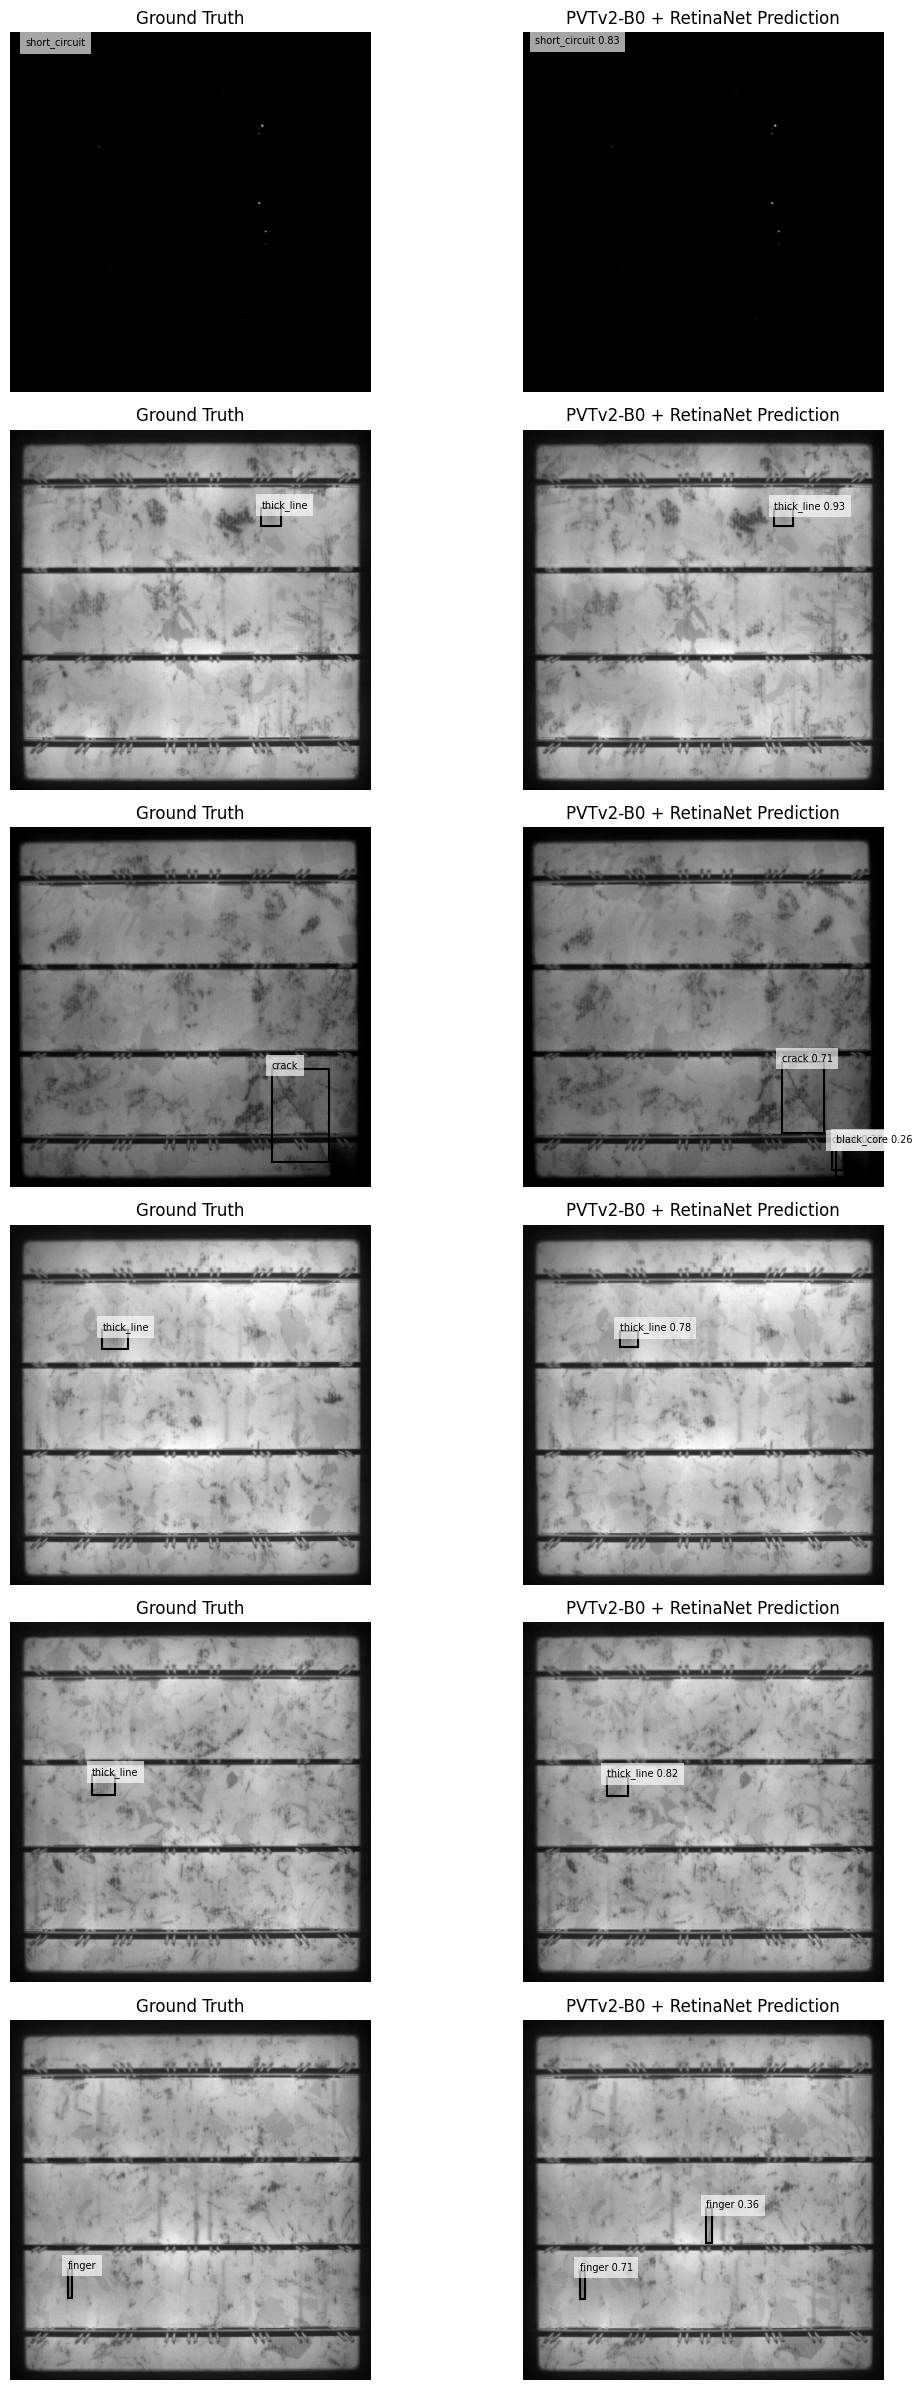

In [ ]:
from matplotlib.patches import Rectangle

def show_box(
    ax,
    box,
    label,
    linewidth=1.5,
):
    x1, y1, x2, y2 = box

    rect = Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=linewidth,
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        max(10, y1),
        label,
        fontsize=7,
        bbox=dict(
            facecolor="white",
            alpha=0.65,
            edgecolor="none",
        ),
    )


defect_indices = [
    i
    for i, target
    in enumerate(test_targets)
    if len(target["boxes"]) > 0
]

random.seed(SEED)

sample_indices = random.sample(
    defect_indices,
    min(
        6,
        len(defect_indices),
    ),
)

fig, axes = plt.subplots(
    len(sample_indices),
    2,
    figsize=(
        12,
        4 * len(sample_indices),
    ),
)

if len(sample_indices) == 1:
    axes = np.array([axes])

for row, idx in enumerate(
    sample_indices
):
    image_tensor, gt, _ = (
        test_dataset[idx]
    )

    image_np = (
        image_tensor
        .permute(1, 2, 0)
        .numpy()
        .clip(0, 1)
    )

    pred = test_predictions[idx]

    axes[row, 0].imshow(
        image_np
    )

    for box, cls_id in zip(
        gt["boxes"].numpy(),
        gt["labels"].numpy(),
    ):
        show_box(
            axes[row, 0],
            box,
            CLASS_NAMES[
                int(cls_id)
            ],
        )

    axes[row, 0].set_title(
        "Ground Truth"
    )

    axes[row, 0].axis("off")

    axes[row, 1].imshow(
        image_np
    )

    keep = (
        pred["scores"]
        >= CONF_THRESHOLD
    )

    for (
        box,
        cls_id,
        score,
    ) in zip(
        pred["boxes"][keep].numpy(),
        pred["labels"][keep].numpy(),
        pred["scores"][keep].numpy(),
    ):
        show_box(
            axes[row, 1],
            box,
            (
                f"{CLASS_NAMES[int(cls_id)]} "
                f"{score:.2f}"
            ),
        )

    axes[row, 1].set_title(
        "PVTv2-B0 + RetinaNet Prediction"
    )

    axes[row, 1].axis("off")

plt.tight_layout()

plt.savefig(
    PLOTS_DIR
    / "ground_truth_vs_prediction.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 24. Model complexity

In [ ]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

model_size_mb = (
    BEST_PT.stat().st_size
    / 1024**2
    if BEST_PT.exists()
    else np.nan
)

model_info_df = pd.DataFrame([{
    "model":
        "PVTv2-B0 + BiMamba + FPN + RetinaNet",

    "parameters":
        total_params,

    "parameters_M":
        total_params / 1e6,

    "trainable_parameters":
        trainable_params,

    "trainable_parameters_M":
        trainable_params / 1e6,

    "mamba_parameters_M":
        sum(
            p.numel()
            for p in model.backbone.deep_mamba.parameters()
        ) / 1e6,

    "best_checkpoint_size_MB":
        model_size_mb,
}]).round(4)

model_info_df.to_csv(
    METRICS_DIR
    / "model_info.csv",
    index=False,
)

display(model_info_df)

,model,parameters,parameters_M,trainable_parameters,trainable_parameters_M,mamba_parameters_M,best_checkpoint_size_MB
0,PVTv2-B0 + BiMamba + FPN + RetinaNet,11912406,11.9124,11912406,11.9124,0.4383,45.4984


# 25. Final model summary

This only summarizes values already calculated above.  
It does **not** retrain or re-run the test set.

In [ ]:
history_df = pd.read_csv(
    METRICS_DIR
    / "training_history.csv"
)

epochs_completed = int(
    history_df["epoch"].max()
)

best_epoch = int(
    history_df.loc[
        history_df[
            "val/mAP50-95"
        ].idxmax(),
        "epoch",
    ]
)

early_stopped = (
    epochs_completed
    < MAX_EPOCHS
)

final_summary_df = pd.DataFrame([{
    "Model":
        "PVTv2-B0 + BiMamba + FPN + RetinaNet",

    "Experiment":
        "A1_Aug_Mamba",

    "Epochs Completed":
        epochs_completed,

    "Best Epoch":
        best_epoch,

    "Early Stopped":
        early_stopped,

    "Precision":
        test_precision,

    "Recall":
        test_recall,

    "F1":
        test_f1,

    "mAP@50":
        test_map50,

    "mAP@75":
        test_map75,

    "mAP@50-95":
        test_map50_95,

    "Mean Box IoU":
        mean_iou,

    "Mean Box Dice":
        mean_dice,

    "Matched Boxes":
        len(matched_ious),

    "Parameters (M)":
        total_params / 1e6,

    "Trainable Parameters (M)":
        trainable_params / 1e6,

    "Model Size (MB)":
        model_size_mb,

    "Physical Batch":
        BATCH_SIZE,

    "Gradient Accumulation":
        ACCUM_STEPS,

    "Effective Batch":
        EFFECTIVE_BATCH,

    "Mean Train Time/Epoch (min)":
        history_df[
            "train_seconds"
        ].mean() / 60,

    "Mean Val-Loss Time/Epoch (min)":
        history_df[
            "val_loss_seconds"
        ].mean() / 60,

    "Mean Val-mAP Time/Epoch (min)":
        history_df[
            "val_map_seconds"
        ].mean() / 60,

    "Mean Total Time/Epoch (min)":
        history_df[
            "total_seconds"
        ].mean() / 60,

    "Total Training Run Time (min)":
        history_df[
            "total_seconds"
        ].sum() / 60,

    "Peak VRAM (GB)":
        history_df[
            "peak_vram_GB"
        ].max(),

    "Inference (ms/image)":
        inference_ms,

    "FPS":
        fps,
}]).round(4)

print("=" * 78)

print(
    "PVTv2-B0 + RETINANET "
    "AUGMENTED — FINAL MODEL SUMMARY"
)

print("=" * 78)

display(final_summary_df)

print(
    "\nPER-CLASS TEST PERFORMANCE"
)

display(per_class_df)

final_summary_df.to_csv(
    METRICS_DIR
    / "final_model_summary.csv",
    index=False,
)

print("\nSaved:")

print(
    METRICS_DIR
    / "final_model_summary.csv"
)

print(
    METRICS_DIR
    / "final_per_class_summary.csv"
)

PVTv2-B0 + RETINANET AUGMENTED — FINAL MODEL SUMMARY


,Model,Experiment,Epochs Completed,Best Epoch,Early Stopped,Precision,Recall,F1,mAP@50,mAP@75,...,Gradient Accumulation,Effective Batch,Mean Train Time/Epoch (min),Mean Val-Loss Time/Epoch (min),Mean Val-mAP Time/Epoch (min),Mean Total Time/Epoch (min),Total Training Run Time (min),Peak VRAM (GB),Inference (ms/image),FPS
0,PVTv2-B0 + BiMamba + FPN + RetinaNet,A1_Aug_Mamba,8,3,True,0.7242,0.9194,0.8102,0.9036,0.5953,...,2,16,3.7901,0.364,0.4571,4.6111,36.8889,2.5047,31.0244,32.2326



PER-CLASS TEST PERFORMANCE


,Class,Images,Instances,Box-P,Box-R,Box-F1,mAP50,mAP50-95,Mean Box IoU,Mean Box Dice
0,finger,187,385,0.7479,0.9091,0.8206,0.9112,0.4455,0.7600,0.8637
1,crack,185,231,0.5506,0.8009,0.6526,0.7224,0.4124,0.7860,0.8802
2,black_core,150,152,0.9351,0.9474,0.9412,0.9742,0.8905,0.9436,0.9710
3,thick_line,149,167,0.7581,0.8443,0.7989,0.8608,0.4329,0.7549,0.8603
4,horizontal_dislocation,119,357,1.0000,1.0000,1.0000,1.0000,0.6745,0.8517,0.9199
5,short_circuit,113,113,0.9244,0.9735,0.9483,0.9523,0.9308,0.9696,0.9846
6,vertical_dislocation,16,64,0.2712,1.0000,0.4267,0.9487,0.5083,0.7815,0.8773
7,star_crack,30,33,0.5882,0.9091,0.7143,0.8595,0.4297,0.7492,0.8566
8,printing_error,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Saved:
/content/drive/MyDrive/Study Materials /CSE465/06_PVTv2B0_Mamba_RetinaNet_Aug/metrics/final_model_summary.csv
/content/drive/MyDrive/Study Materials /CSE465/06_PVTv2B0_Mamba_RetinaNet_Aug/metrics/final_per_class_summary.csv


## Notes for A0 vs A1 ablation

**A0**
- PVTv2-B0 + FPN + RetinaNet + final PVT augmentation

**A1**
- PVTv2-B0 + deep bidirectional Mamba + FPN + RetinaNet
- same final PVT augmentation

Controlled variables:
- same prepared train/validation/test split
- same 640×640 input
- same training augmentation
- same detection head and evaluation code
- same confidence/IoU conventions
- same effective batch size
- same seed
- source weights initialized from A0 best checkpoint

A1-specific change:
- one residual bidirectional Mamba block on the deepest PVT feature
  before FPN
- Mamba uses `d_model=256`, `d_state=16`, `d_conv=4`, `expand=2`
- forward and reverse scans share Mamba parameters
- residual gate starts at 0.0
- fine-tuning uses differential learning rates

Validation is used for checkpoint selection and early stopping.
Test evaluation is performed only after selecting the best A1 checkpoint.

## Final Drive checkpoint verification

Do **not disconnect Colab** until this cell confirms that `best.pt` exists in
Google Drive.

In [ ]:
print("=" * 72)
print("FINAL DRIVE PERSISTENCE CHECK")
print("=" * 72)

files_to_verify = [
    BEST_PT,
    LAST_PT,
    METRICS_DIR
    / "final_model_summary.csv",
    METRICS_DIR
    / "final_per_class_summary.csv",
]

missing = []

for path in files_to_verify:
    exists = path.exists()

    if exists:
        size_mb = (
            path.stat().st_size
            / 1024**2
        )

        print(
            f"✅ {path.name:35s} "
            f"{size_mb:8.2f} MB"
        )
    else:
        print(
            f"❌ {path.name:35s} MISSING"
        )
        missing.append(
            str(path)
        )

if missing:
    raise RuntimeError(
        "Some final files are missing from Google Drive. "
        "Do NOT disconnect the runtime yet."
    )

print(
    "\n✅ All required A1 files are safely present in Google Drive."
)

FINAL DRIVE PERSISTENCE CHECK
✅ best.pt                                45.50 MB
✅ last.pt                               136.55 MB
✅ final_model_summary.csv                 0.00 MB
✅ final_per_class_summary.csv             0.00 MB

✅ All required A1 files are safely present in Google Drive.
